### Predgovor
Ova vježba sastoji se od teoretskog i praktičnog dijela. Bez adekvatnog teorijskog razumijevanja, implementacijska izvedba će biti začajno izazovnija.

Predlažemo da napravite kopiju ove bilježnice na svoj Colab profil i tamo riješite vježbu. Ne zaboravite uključiti GPU akceleraciju (Runtime->Change runtime type->GPU->Save). \

U slučaju nejasnoća javite se na anja.delic@fer.hr.

# 4. Laboratorijska vježba - generativno modeliranje

Jedan od glavnih katalizatora u razvoju modernog računalnog vida jest dostupnost velikih skupova podataka. Iako su skupovi podataka lako dostupni, proces koji generira podatke je često nepoznat. Cilj ove laboratorijske vježbe jest pokušati aproksimirati proces koji generira dani skup podataka.


## Teorijska podloga generativnom modeliranju

Krenuti ćemo od bolje definicije zadatka.
Pretpostavimo postojanje skupa podataka $D=\{\mathbf{x}_i\}_{i=1}^N$ koji je nastao uzorkovanjem nepoznate distribucije $P_D(\underline{\mathbf{x}})$. Nadalje, pretpostavimo da je svaki primjer $\mathbf{x}_i$ dobiven nezavisnim uzorkovanjem. Naš cilj je aproksimirati nepoznatu distribuciju podataka $P_D(\underline{\mathbf{x}})$ poznatim modelom $P_\theta(\underline{\mathbf{x}})$.
S obzirom da su naši podaci često u kontinuirani ($\underline{\mathbf{x}}$ je kontinuirana slučajna varijabla) baviti ćemo se modeliranjem gustoća vjerojatnosti $p_D(\underline{\mathbf{x}})$ i $p_\theta(\underline{\mathbf{x}})$.

**Problem 1.:** Kako poravnati nepoznati $p_D(\underline{\mathbf{x}})$ i poznati $p_\theta(\underline{\mathbf{x}})$?



U teoriji vjerojatnosti, različitost između dvije distribucije $P(\underline{x})$ i $Q(\underline{x})$ se mjeri pomoću f-divergencije. Jedna od najčešćih mjera iz obitelji f-divergencija je KL-divergencija. KL-divergenciju za kontinuirane slučajne varijable definiramo kao:
$$
\mathrm{KL}(P, Q) = \int_{-\infty}^{+\infty} p(x) \ln\frac{p(x)}{q(x)} dx.
$$
$p$ i $q$ su pripadajuće gustoće vjerojatnosti.

KL-divergencije između distribucije podataka i distribucije modela je primamljiv gubitak za naš optimizacijski postupak. Može se pokazati da je minimizacija KL divergencije između distribucije podataka i distribucije modela ekvivalentna minimizaciji negativne log-izglednosti skupa podataka za učenje:
$$
\underset{\theta}{\mathrm{min}} \, \mathrm{KL}(p_D, p_\theta) \simeq \underset{\theta}{\mathrm{min}} \, -\mathbb{E}_{\mathbf{x} \in D} \;\;  [\ln p_\theta(\mathbf{x})]
$$

**Zadatak 1.**: Dokažite navedenu tvrdnju.

Dokaz:
$$
\underset{\theta}{\mathrm{min}} \, \mathrm{KL}(p_D, p_\theta) = \mathrm{Nadopuni}
$$
$$
\underset{\theta}{\text{argmin}} \, \mathrm{KL}(P \| Q) = \underset{\theta}{\text{argmin}} \, \mathbb{E}_{x \sim P}[-\log Q_\theta(X)] - H(P(X)) = \underset{\theta}{\text{argmin}} \, \mathbb{E}_{x \sim P}[-\log Q_\theta(X)] = \underset{\theta}{\text{argmax}} \, \mathbb{E}_{x \sim P}[\log Q_\theta(X)]
$$


**Problem 2.**: Definicija modela $p_\theta$.

Naš sljedeći korak je definirati model $p_\theta$. Upravo po definiciji  $p_\theta$ razlikujemo različite generativne modele.
Na primjer autoregresivna faktorizacija modela dovodi do autoregresijskih modela, dok modeliranje nenormalizirane distribucije dovodi do energijskih modela. U ovoj vježbi se fokusiramo  na vrstu generativnih modela koje nazivamo normalizirajući tokovi. Normalizirajući tok $p_\theta$ definiramo pomoću formule za zamjenu varijabli distribucije.

Pretpostavimo da su $\underline{\mathbf{x}}$ i $\underline{\mathbf{z}}$ dvije kontinuirane slučajne varijable. Pretpostavimo da bijekcija $f$ mapira realizacije slučajne varijable $\underline{\mathbf{x}}$ u realizacije od $\underline{\mathbf{z}}$, to jest $\mathbf{z} = f(\mathbf{x})$. S obzirom da je $f$ bijekcija vrijedi i obrat $\mathbf{x} = f^{-1}(\mathbf{z})$. Formulu za zamjenu varijabi distribucije definiramo kao:
$$
 p(\mathbf{x}) = q(\mathbf{z}) \left| \mathrm{det} \frac{\partial \mathbf{z}}{ \partial \mathbf{x}} \right|, \quad \mathbf{z} = f(\mathbf{x})
$$
$\frac{∂ \mathbf{z}}{ ∂ \mathbf{x}}$ predstavlja Jakobijan funkcije $f$ za $\textbf{x}$. det predstavlja determinantu. $|\cdot|$ predstavlja apsolutnu vrijednost.
To jest, drugi član umnoška odgovara apsolutnoj vrijednosti determinante Jakobijana transformacije $f$.

Formulu za zamjenu varijabli ćemo iskoristiti za izgradnju okvira koji nam omogućava implementaciju dubokog generativnog modela.
Ideja je jednostavna, distribuciju $q(\mathbf{z})$ možemo predefinirati (npr. kao Gaussovu distribuciju). Tada nam je jedina nepoznanica bijekcija $f$ koju možemo parametrizirati s $\theta$ te naučiti optimizacijskim postupkom.


Prisjetimo se sljedećih teorema:
1. kompozicija bijekcija je bijekcija, tj $f$ možemo raspisati kao $f = f_1 ∘ f_2 ∘ f_3 ∘ \dots \circ f_K$.
2. pravilo ulančavanja: $\frac{∂ z_3}{ ∂ z_1} = \frac{∂ z_3}{ ∂ z_2}\frac{∂ z_2}{ ∂ z_1} $
3. determinanta umnoška dviju kvadratnih matrica istog reda jednaka je umnošku determinanti svake matrice (Binet-Cauchyjev teorem)
4. Apsolutna vrijednost umnoška dva realna broja je jednaka umnošku apsolutnih vrijednosti: $|a\cdot b| = |a|\cdot |b|$

Bijekciju $f$ možemo promatrati kao kompoziciju funkcija, gdje svaka funkcija $f_i$ prima varijablu $z_{i-1}$ i računa varijablu $z_i$.
Ako uzmemo u obzir prethodno spomenute teoreme, dolazimo do sljedeće formulacije:
$$
 p_\theta (\mathbf{x}) = q(\mathbf{z}_K) \prod_{k=1}^K \left| \mathrm{det} \frac{\partial \mathbf{z}_{k} }{ \partial \mathbf{z}_{k-1}} \right|, \quad \mathbf{z}_{k} = f_{\theta_k}(\mathbf{z}_{k-1}),
$$
gdje je $\mathbf{z}_{0} = \mathbf{x}$.
$q(\mathbf{z}_K)$ može biti proizvoljna distribucija pa je definiramo kao $q(\mathbf{z}_K):= \mathcal{N}(\mathbf{z}_K; 0, \mathrm{I})$.

**Zadatak 2.** Krenuvši od općenite formule za zamjenu varijabli izvedite izraz za normalizirajući tok.

Izvod:
$$
p(\mathbf{x}) = q(\mathbf{z}_K) \left| \mathrm{det} \frac{\partial f(\mathbf{x})}{ \partial \mathbf{x}} \right| \\
z \sim q_\theta(z_K) \\
x = f_\theta(z) = f_K \circ \cdots \circ f_2 \circ f_1(z) \\
p_\theta(x) = q(z_K) \prod_{i=1}^K \left| \det \left( \frac{\partial z_K}{\partial z_{K-1}} \right) \right| 
$$

Spomenimo još da nas općenito zanima logaritam gustoće vjerojatnosti pa pišemo:
$$
 \ln p_\theta (\mathbf{x}) = \ln q(\mathbf{z}_K) +\sum_{k=1}^K \ln \left| \mathrm{det} \frac{\partial \mathbf{z}_{k} }{ \partial \mathbf{z}_{k-1}} \right|, \quad \mathbf{z}_{k} = f_{\theta_k}(\mathbf{z}_{k-1}), \tag{1}
$$

Ostala nam je još jedna nepoznanica, a to je dizajn funkcija $f_k$,  $k=1,...,K$.
Dizajn funkcije f ovisi o podacima koje modeliramo. Razmislite kako biste bijekciju modelirali kao gradivni blok dubokog modela.

## Modeliranje 2D skupa podataka normalizirajućim tokom

**Problem 3.** Modeliranje 2D skupa podatka.

In [1]:
import torch
import random
import numpy as np
import torch.nn as nn

np.random.seed(0)
random.seed(0)
torch.manual_seed(0)

import matplotlib.pyplot as plt

In [2]:
class GaussianMixture2DDataset:
    def __init__(self, num_samples, n_comp=2, loc=torch.zeros(2,2), scale=torch.ones(2,2), pi=(torch.ones(2)/2)):
        samples_per_component = (pi * num_samples).long()
        self.samples = torch.cat([torch.randn(samples_per_component[i],2) * scale[i] + loc[i] for i in range(n_comp)], 0)

    def __getitem__(self, idx):
        return self.samples[idx]

Promotrimo sljedeći skup podataka. Pretpostavimo da nam je dostupan samo skup podataka $D$. Cilj nam je aproksimirati distribuciju podataka $p_D$ pomoću normalizirajućeg toka.

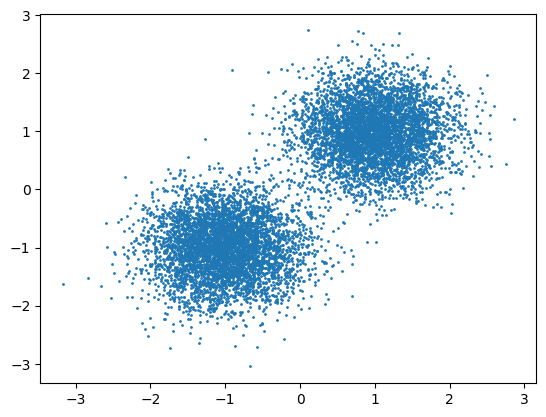

In [3]:
D = GaussianMixture2DDataset(9999, loc=torch.tensor([[-1, -1], [1,1]]), scale=torch.tensor([[0.5, 0.5], [0.5,0.5]])).samples
plt.scatter(D[:, 0], D[:, 1], 1)
plt.show()

S obzirom da modeliramo 2D skup podatka, zanimaju nas funkcije s domenom $\mathbb{R}^2$ i kodomenom $\mathbb{R}^2$ koje imaju inverz.
Definiramo sljedeći implementacijski ovir:

In [4]:
class _Bijection(nn.Module):
    def __init__(self):
        super(_Bijection, self).__init__()

    def forward(self, x):
        pass

    def inverse(self, z):
        pass

Funkcija `forward` implementira unaprijedni probalz kroz sloj i na izlazu vraća transformirani ulaz i logaritam apsolutne vrijednosti determinante Jakobijana funkcije. \
Funkcija `inverse` implementira inverzni probalz kroz sloj i na izlazu vraća transformirani ulaz.

**Zadatak 3.**: Pokušajmo ponuditi bijektivnu alternativu sloju torch.nn.Linear.Obratite pozornost na to da je transformaciju potrebno održavati invertibilnom regularizacijskim članom.
Nadopunite forward i inverse funkciju.

Hint: Linearna transformacija se primjenjuje na svaki primjer u minigrupi nezavisno.

In [5]:
def sum_except_batch(x, num_dims=1):
    return x.reshape(*x.shape[:num_dims], -1).sum(-1)

class BijectiveLinear(_Bijection):
    def __init__(self, dim):
        super(_Bijection, self).__init__()
        self.dim = dim
        self.weight = nn.Parameter(torch.eye(dim))
        self.bias = nn.Parameter(torch.zeros(1, dim))

    def forward(self, x):   # x has shape NxD
        z = torch.matmul(x, self.weight) + self.bias
        log_abs_det = sum_except_batch(torch.log(torch.abs(torch.det(self.weight)))) # N
        return z, log_abs_det # shapes NxD, N

    def inverse(self, z):
        x = torch.matmul(z - self.bias, torch.inverse(self.weight))
        if torch.isnan(x).any():
            print("x is nan")
        return x    # NxD

    def regularization(self):
        return ((self.weight @ self.weight) - torch.eye(self.dim)).abs().sum()

**Zadatak 4.**: Nadopunite implementaciju baznog razreda `NormalizingFlow`.

Obratite pozornost na to da razred kroz konstruktor prima atribut `transforms` koji mora biti tipa [torch.nn.Sequential](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) kako bismo kroz taj objekt mogli iterirati koristeći for petlju kroz slojeve normalizirajućeg toka pri unaprijednom i inverznom prolazu. Pretpostavka je da će svi elementi u transforms nasljeđivati prethodno definirano sučelje `_Bijection`.



In [6]:
import torch
import torch.nn as nn
import torch.distributions

class NormalizingFlow(nn.Module):
    """
    Base class for normalizing flow.
    """

    def __init__(self, transforms, input_dim):
        super(NormalizingFlow, self).__init__()
        self.transforms = transforms # has to be of type nn.Sequential.

        self.register_buffer('loc', torch.zeros(input_dim))
        self.register_buffer('log_scale', torch.zeros(input_dim))
        self.base_dist = torch.distributions.Normal(self.loc, torch.exp(self.log_scale))

    def forward(self, x):
        """Transforms the input sample to the latent representation z.

        Args:
            x (torch.Tensor): input sample

        Returns:
            torch.Tensor: latent representation of the input sample
        """
        # ...
        z = x
        for transform in self.transforms:
            z, log_det = transform(z)
        return z

    def inverse(self, z):
        """Transforms the latent representation z back to the input space.

        Args:
            z (torch.Tensor): latent representation

        Returns:
            torch.Tensor: representation in the input space
        """
        # ...
        x = z
        for transform in reversed(self.transforms):
            x = transform.inverse(x)
        return x

    def log_prob(self, x):
        """Calculates the log-likelihood of the given sample x (see equation (1)).

        Args:
            x (torch.Tensor): input

        Returns:
            torch.Tensor: log-likelihood of x
        """
        z = self.forward(x)
        log_abs_det_all = 0
        for transform in self.transforms:
            _, log_abs_det = transform(z)
            log_abs_det_all += log_abs_det
        log_pz = torch.sum(self.base_dist.log_prob(z), dim=-1)
        log_px =  log_pz + log_abs_det_all
        return log_px

    def sample(self, num_samples, T=1):
        """Generates new samples from the normalizing flow.

        Args:
            num_samples (int): number of samples to generate
            T (float, optional): sampleing temperature. Defaults to 1.

        Returns:
            torch.Tensor: generated samples
        """
        z = self.base_dist.sample(torch.Size([num_samples])) * T
        x = self.inverse(z)
        return x

U jednostavnom slučaju, transformaciju normalizirajućeg toka možemo definirati kao slijed linearnih transformacija:

In [7]:
class SimpleNF(NormalizingFlow):
    def __init__(self, input_dim, num_steps=2):
        transforms = nn.Sequential()
        for _ in range(num_steps):
            transforms.append(BijectiveLinear(input_dim))
            transforms.append(nn.Tanh())

        super(SimpleNF, self).__init__(transforms=transforms, input_dim=input_dim)

    def gather_regularization(self):
        return sum([m.regularization() for m in self.transforms])

Provjerite svoju implementaciju inverza sljedećim kodom:

In [8]:
flow = SimpleNF(2, num_steps=7)
print((flow.inverse(flow(D)) - D).sum().item())
assert (flow.inverse(flow(D)) - D).sum() < 1e-9

0.0


Tok učimo optmizacijom prethodno objašnjenog gubitka.

In [9]:
flow = SimpleNF(2, num_steps=7)
optim = torch.optim.SGD(flow.parameters(), lr=1e-1)

for iter in range(4000):
    optim.zero_grad()
    log_px = flow.log_prob(D)
    loss = - (log_px).mean()
    loss_reg = flow.gather_regularization()
    loss_reg = loss_reg / 9999
    total_loss = loss + 0.001 * loss_reg
    total_loss.backward()
    optim.step()
    if iter % 20 == 0:
        print(f"Iter {iter+1}: Loss:{loss.item()} Reg:{loss_reg.item()}")

Iter 1: Loss:3.0862061977386475 Reg:0.0
Iter 21: Loss:2.546750068664551 Reg:3.0695765018463135
Iter 41: Loss:2.5738589763641357 Reg:3.1125833988189697
Iter 61: Loss:2.548732042312622 Reg:3.1985695362091064
Iter 81: Loss:2.5468015670776367 Reg:3.201481342315674
Iter 101: Loss:2.54664945602417 Reg:3.1980490684509277
Iter 121: Loss:2.5466349124908447 Reg:3.1942155361175537
Iter 141: Loss:2.546633243560791 Reg:3.1904401779174805
Iter 161: Loss:2.546633243560791 Reg:3.1867754459381104
Iter 181: Loss:2.546633243560791 Reg:3.1832189559936523
Iter 201: Loss:2.546633243560791 Reg:3.1797659397125244
Iter 221: Loss:2.546632766723633 Reg:3.1764183044433594
Iter 241: Loss:2.546632766723633 Reg:3.1731693744659424
Iter 261: Loss:2.546632766723633 Reg:3.170016050338745
Iter 281: Loss:2.546632766723633 Reg:3.166959762573242
Iter 301: Loss:2.546633243560791 Reg:3.1639890670776367
Iter 321: Loss:2.546633243560791 Reg:3.161109447479248
Iter 341: Loss:2.546632766723633 Reg:3.1583189964294434
Iter 361: Loss

Provjerimo još jednom stabilnost inverza. Kako biste komentrali rezultate?

In [10]:
print((flow.inverse(flow(D)) - D).sum())
assert (flow.inverse(flow(D)) - D).sum() < 1e-4

tensor(3.0365e-05, grad_fn=<SumBackward0>)


Normalizirajućim tokom možemo generirati primjere na sljedeći način:

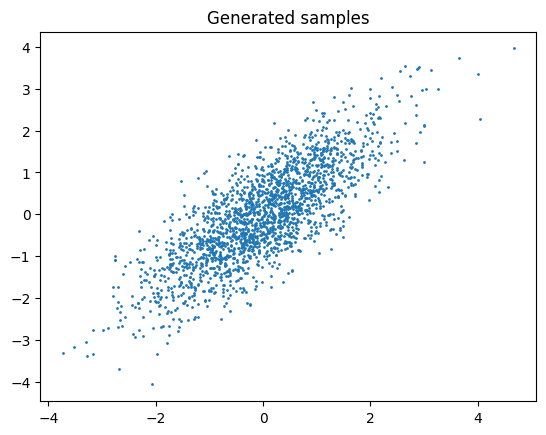

In [11]:
X_ = flow.sample(2000).detach()
plt.scatter(X_[:, 0], X_[:, 1], 1)
plt.title("Generated samples")
plt.show()

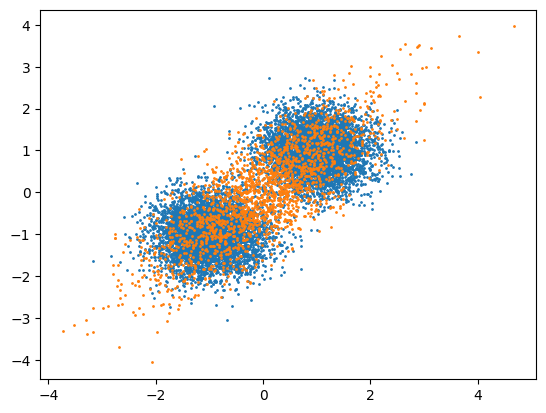

In [12]:
plt.clf()
plt.scatter(D[:, 0], D[:, 1], 1)
plt.scatter(X_[:, 0], X_[:, 1], 1)
plt.show()

Definirani tok je prilično jednostavan stoga ne uspijeva dovoljno dobro aproksimirati $p_D$. Bolju performansu dobiti ćemo s kapacitetnijim tokom pod nazivom [RealNVP](https://arxiv.org/abs/1605.08803). RealNVP se sastoji od Coupling slojeva koji su invertibilni po konstrukciji.

Unaprijedni prolaz kroz afini coupling sloj s ulazom $\mathbf{x}$ dimenzionalnosti $d$ definiramo kao ($m < d$):
$$
\mathbf{z}_{:m} = \mathbf{x}_{:m}
$$
$$
\mathbf{z}_{m:d} = \exp(\ln\mathbf{s}) \odot \mathbf{x}_{m:d} + \mathbf{t}, \quad \ln s, t = net(\mathbf{x}_{:m})
$$

**Zadatak 5.**: Skicirajte računske grafove unaprijednog i unatražnog prolaza kroz afini coupling sloj. \
Nadopunite postojeći `AffineCouplingLayer` s prikladnom funkcionalnošću.
Coupling sloj transformira samo polovicu ulaznog tezora $\mathbf{x}_{m:d}$, a druga polovica $\mathbf{x}_{:m}$ ostaje ista.
Modul miješanja `net` na izlazu predviđa parametre miješanja `log_s` i `t` iz iz polovice ulaznog tenzora $\mathbf{x}_{:m}$.

In [13]:
class AffineCouplingLayer(_Bijection):
    def __init__(self, net):
        super(AffineCouplingLayer, self).__init__()
        self.net = net

    def forward(self, x): # NxD
        # ...
        x1, x2 = torch.chunk(x, 2, dim=1)
        log_s, t = self.net(x1)
        s = torch.exp(log_s)
        z2 = s * x2 + t
        z = torch.cat((x1, z2), dim=1)
        log_det = sum_except_batch(log_s)
        return z, log_det # NxD , N

    def inverse(self, y): # NxD
        # ...
        y1, y2 = torch.chunk(y, 2, dim=1)
        log_s, t = self.net(y1)
        s = torch.exp(-log_s)
        x2 = (y2 - t) * s
        x = torch.cat((y1, x2), dim=1)
        return x

**Zadatak 6.:** Zamislimo situaciju gdje slijedno primjenjujemo više coupling slojeva. Možemo primijetiti da će se miješati samo jedna polovica tenzora. Kako bismo osigurali da se miješaju obje polovice ulaznog tenzora, uvodimo transformaciju `SwitchSides` koju ćemo primijeniti nakon svakog coupling sloja.
Na taj način osiguravamo da miješanje provodimo naizmjenično na dvjema polovicama ulaznog tenzora. \
Tenzor dijelimo po dimenziji značajki. Dovršite implementaciju razreda `SwitchSides` tako da dijeli ulazni tenzor na dva dijela po dimenziji značajki i zamjenjuje im strane. Možete iskoristiti funkcije [chunk](https://pytorch.org/docs/stable/generated/torch.chunk.html) i [cat](https://pytorch.org/docs/stable/generated/torch.cat.html).

In [14]:
class SwitchSides(_Bijection):

    def forward(self, x):
        # ...
        x1, x2 = torch.chunk(x, 2, dim=1)
        y = torch.cat((x2, x1), dim=1)
        return y, 0.

    def inverse(self, z):
        # ...
        z1, z2 = torch.chunk(z, 2, dim=1)
        x = torch.cat((z2, z1), dim=1)
        return x

**Zadatak 7.:** U nastavku je dan razred `SimpleTransform` kojeg ćemo koristiti kao modul afinog miješanja u coupling sloju. Primijetite da je to atribut `net` razreda `AffineCouplingLayer`.\
Dovršite implementaciju tako da `model` bude potpuno povezani modul sljedeće arhitekture:

`fc(dim, internal_dim) -> relu -> fc(internal_dim, internal_dim) -> relu -> fc(internal_dim, 2*dim)`.

Dimenziju skrivenog sloja potpuno povezanog modula određujemo parametrom `inflate_coef`. \


Inlicijalizirajte parametre modula miješanja tako da modul provodi transformaciju koja je jednaka identitetu. \

In [15]:
class SimpleTransform(nn.Module):
    def __init__(self, dim, inflate_coef=1):
        super(SimpleTransform, self).__init__()
        self.dim = dim
        internal_dim = int(dim * inflate_coef)
        self.model = nn.Sequential(
            nn.Linear(dim, internal_dim),
            nn.ReLU(),
            nn.Linear(internal_dim, internal_dim),
            nn.ReLU(),
            nn.Linear(internal_dim, dim * 2),
        )
        
        with torch.no_grad():
            for layer in self.model:
                if isinstance(layer, nn.Linear):
                    nn.init.zeros_(layer.weight)
                    nn.init.zeros_(layer.bias)
                    layer.weight += torch.eye(layer.weight.shape[0])
                    layer.bias += torch.zeros(layer.bias.shape) 


    def forward(self, x):
        out = self.model(x)
        log_s, t = torch.chunk(out, dim=1, chunks=2)
        return log_s, t

In [16]:
class SimpleRealNVP(NormalizingFlow):
    def __init__(self, input_dim, num_steps=2):
        transforms = nn.Sequential()
        for i in range(num_steps):
            transforms.append(AffineCouplingLayer(SimpleTransform(input_dim//2)))
            if i != num_steps - 1:
                x = input_dim // 2
                input_dim = input_dim - x
                transforms.append(SwitchSides())
        super(SimpleRealNVP, self).__init__(transforms, input_dim)


Tok možemo naučiti na način kako slijedi:

In [17]:
flow = SimpleRealNVP(2, num_steps=7)
optim = torch.optim.SGD(flow.parameters(), lr=1e-2, nesterov=True, momentum=0.9)

for iter in range(2000):
    optim.zero_grad()
    log_px = flow.log_prob(D)
    loss = - (log_px).mean()
    total_loss = loss
    loss.backward()
    total_loss.backward()
    optim.step()

    if iter % 20 == 0:
        print(f"Iter {iter+1}: Loss:{loss.item()}")

Iter 1: Loss:3.0862061977386475
Iter 21: Loss:3.0598955154418945
Iter 41: Loss:3.0596628189086914
Iter 61: Loss:3.0596470832824707
Iter 81: Loss:3.0596466064453125
Iter 101: Loss:3.0596468448638916
Iter 121: Loss:3.0596468448638916
Iter 141: Loss:3.0596468448638916
Iter 161: Loss:3.0596466064453125
Iter 181: Loss:3.0596466064453125
Iter 201: Loss:3.0596466064453125
Iter 221: Loss:3.0596466064453125
Iter 241: Loss:3.0596466064453125
Iter 261: Loss:3.0596466064453125
Iter 281: Loss:3.0596466064453125
Iter 301: Loss:3.0596466064453125
Iter 321: Loss:3.0596466064453125
Iter 341: Loss:3.0596468448638916
Iter 361: Loss:3.0596468448638916
Iter 381: Loss:3.0596466064453125
Iter 401: Loss:3.0596468448638916
Iter 421: Loss:3.0596466064453125
Iter 441: Loss:3.0596466064453125
Iter 461: Loss:3.0596466064453125
Iter 481: Loss:3.0596466064453125
Iter 501: Loss:3.0596468448638916
Iter 521: Loss:3.0596468448638916
Iter 541: Loss:3.0596466064453125
Iter 561: Loss:3.0596468448638916
Iter 581: Loss:3.059

In [18]:
print((flow.inverse(flow(D)) - D).sum())
assert (flow.inverse(flow(D)) - D).sum() < 1e-4

tensor(1.9018e-05, grad_fn=<SumBackward0>)


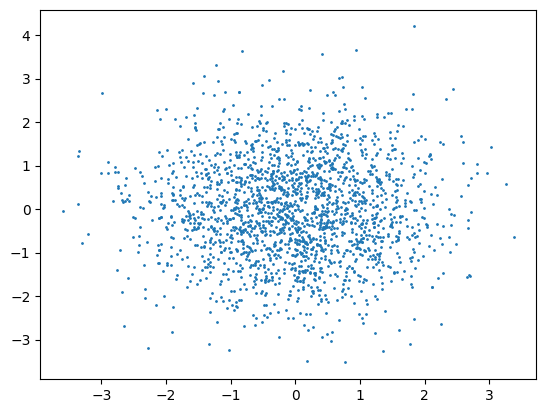

In [19]:
X_ = flow.sample(2000, 1).detach()
plt.scatter(X_[:, 0], X_[:, 1], 1)
plt.show()

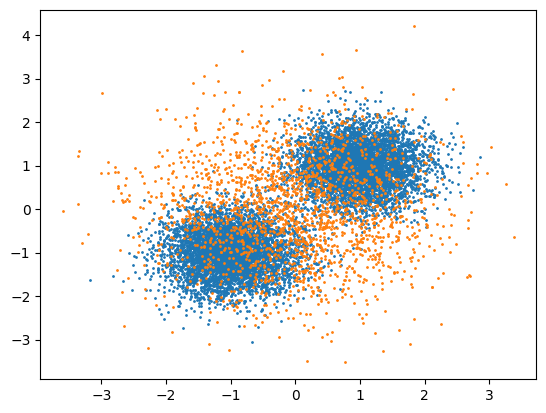

In [20]:
plt.clf()
plt.scatter(D[:, 0], D[:, 1], 1)
plt.scatter(X_[:, 0], X_[:, 1], 1)

Kao što vidite, kapacitetniji tok uspijeva dobro aproksimirati dani skup podataka.

## Modeliranje slika normalizirajućim tokom

Naš sljedeći zadatak je modelirati distribuciju slika s normalizirajućim tokom. Slike možemo prestaviti diskretnim tenzorom $\mathbf{x} \in [0, 255]^{C \times H \times W}$. Prisjetimo se da smo normalizirajući tok definirali za kontinuirane slučajne varijable. Stoga, potrebno je transfrormirati skup podataka u kontinuiranu domenu pomoću zašumljivanja:

$$
\mathbf{y} = \mathbf{x} + \mathbf{u}, \quad \mathbf{u} \sim \mathrm{U}[0, 1)
$$
U prestavlja uniformnu razdiobu. Sada, naš model uči modelirati zašumljenu sliku. Više o dekvantizaciji zašumljivanjem možete pronaći [ovdje](https://arxiv.org/pdf/1511.01844.pdf).

MNIST je skup jednostavnih slika pa ćemo se sljedećim pojednostavljenjem. Sliku ćemo ispeglati u vektor i normalizirajućim tokom učiti takvu reprezentaciju slike.

U nastavku je dan kod za pripremanje skupa slika.

In [21]:
from torchvision.datasets import MNIST
import torchvision.transforms as tf
from torch.utils.data import DataLoader, Subset

In [22]:
train_ds = MNIST('.', train=True, download=True, transform=tf.Compose([tf.Resize(14), tf.ToTensor()]))
test_ds = MNIST('.', train=False, download=True, transform=tf.Compose([tf.Resize(14), tf.ToTensor()]))

selected_number = 0
x_sn = train_ds[0][0].numpy()
plt.imshow(x_sn[0], cmap='gray')

indices = [r[0] for r in list(filter(lambda x: x[1] == selected_number ,[(i, train_ds[i][1]) for i in range(len(train_ds))]))]
train_ds = Subset(train_ds, indices)

indices = [r[0] for r in list(filter(lambda x: x[1] == selected_number ,[(i, test_ds[i][1]) for i in range(len(test_ds))]))]
test_ds = Subset(test_ds, indices)

in_x = train_ds[0][0].numpy()
plt.imshow(in_x[0], cmap='gray')

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

In [23]:
def plot_mnist(samples, num_row, num_col):
    assert len(samples) ==  num_row * num_col
    fig, axes = plt.subplots(num_row, num_col, figsize=(1.5*num_col,2*num_row))
    for i in range(len(samples)):
        ax = axes[i//num_col, i%num_col]
        ax.imshow(samples[i], cmap='gray')
    plt.tight_layout()
    plt.show()

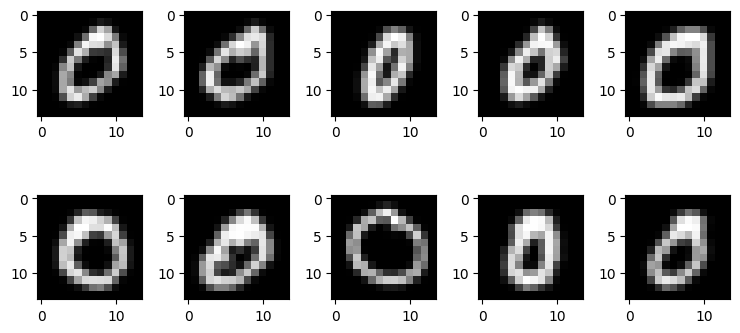

In [24]:
samples = [train_ds[i][0][0] for i in range(10)]
plot_mnist(samples, 2, 5)

**Zadatak 8.:** Predložite arhitekturu toka koji će moći naučiti distribuciju vektoriziranih slika. Predlažemo koristiti rezidualni blok sljedeće arhitekture.

`fc(dim, dim) -> BN -> relu -> fc(dim, dim) -> relu`

Potrebno je dodati rezidualnu vezu od ulaza u rezidualni blok do latentne reprezentacije prije posljednje zglobnice.
Dovršite implementaciju i validirajte utjecaj batchnorma na proces učenja i konačne rezultate.

In [25]:
class ResidualBlock(nn.Module):
    def __init__(self, dim, use_bn=False):
        super(ResidualBlock, self).__init__()
        self.layers = nn.Sequential()
        err = "ResidualBlock only supports dimensions of 1 or 3"
        if dim == 1:
            self.layers.add_module('linear1', nn.Linear(1, 1))
            self.layers.add_module('relu1', nn.ReLU())
            self.layers.add_module('linear2', nn.Linear(1, 1))
        layers = []
        layers.append(nn.Linear(dim, dim))
        if use_bn:
            layers.append(nn.BatchNorm1d(dim))
        layers.append(nn.ReLU())
        for _ in range(3):
            layers.append(nn.Linear(dim, dim))
            if use_bn:
                layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(dim, dim))
        self.layers = nn.Sequential(*layers)
        self.f_relu = nn.ReLU()

    def forward(self, x):
        identity = x
        out = self.layers(x)
        out = out + identity
        return self.f_relu(out)

**Zadatak 9.:** Po uzoru na razred `SimpleTransform` dovršite implementaciju razreda `SimpleResidualTransform` čiji se modul miješanja sastoji od rezidualnih blokova. Predlažemo sljedeću arhitekturu:

`fc(dim, internal_dim) -> relu -> res_block(internal_dim, internal_dim) -> fc(internal_dim, 2*dim)`

Eksperimentirajte s brojem rezidualnih blokova. Kako broj rezidualnih blokova utječe na rezultate?

In [26]:
class SimpleResidualTransform(nn.Module):
    def __init__(self, dim, inflate_coef=1):
        super(SimpleResidualTransform, self).__init__()
        self.dim = dim
        xz = int(dim * inflate_coef)
        internal_dim = int(dim * inflate_coef)
        self.model = nn.Sequential(
            nn.Linear(dim, internal_dim),
            nn.ReLU(),
            ResidualBlock(internal_dim),
            nn.Linear(internal_dim, dim * 2),
        )
        with torch.no_grad():
            for layer in self.model:
                if isinstance(layer, nn.Linear):
                    nn.init.zeros_(layer.weight)
                    nn.init.zeros_(layer.bias)

        if inflate_coef != 1:
            self.model[2].layers[0].weight.data *= 0.1
            self.model[2].layers[2].weight.data *= 0.1
            self.model[2].layers[0].bias.data *= 0.1
            self.model[2].layers[2].bias.data *= 0.1

    def forward(self, x):
        # ...
        out = self.model(x)
        log_s, t = torch.chunk(out, dim=1, chunks=2)
        return log_s, t

**Zadatak 10.:** Dovršte implementaciju razreda `RealNVP` po uzoru na `SimpleRealNVP`. `RealNVP` treba koristiti `SimpleResidualTransform` umjesto `SimpleTransform` kao modul miješanja.

In [27]:
class RealNVP(NormalizingFlow):
    def __init__(self, input_dim, num_steps=2):
        transforms = nn.Sequential()
        for i in range(num_steps):
            transforms.append(AffineCouplingLayer(SimpleResidualTransform(input_dim//2)))
            if i != num_steps - 1:
                transforms.append(SwitchSides())
            if i != num_steps - 1:
                transforms.append(SwitchSides())
        super(RealNVP, self).__init__(transforms, input_dim)

U nastavku je kod za učenje toka.

Obratite pozornost na to da izglednost slike prikazujemo u bitovima po dimenziji (BPD). Podsjetite se što ta mjera predstavlja i kako ju računamo.

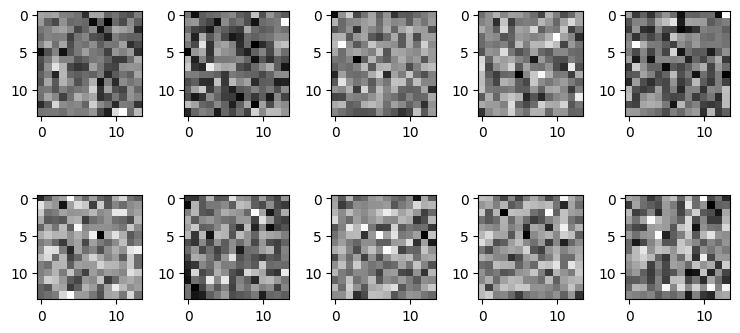

Epoch 1: Train Loss:1275.957402655419 Val BPD: 9.376664161682129


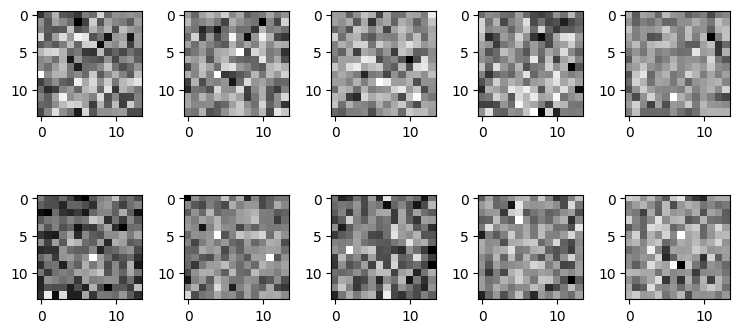

Epoch 11: Train Loss:1218.8250212973737 Val BPD: 8.941740036010742


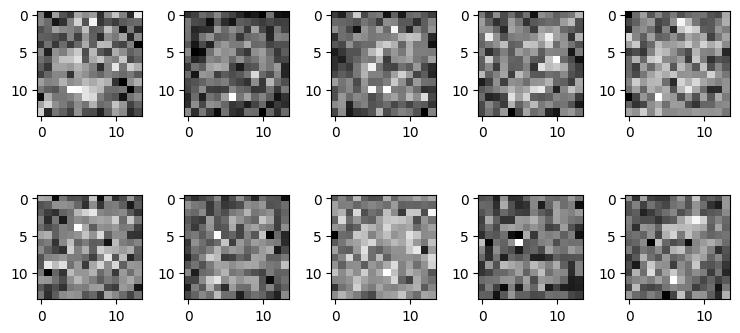

Epoch 21: Train Loss:1125.5887139502993 Val BPD: 8.24374771118164


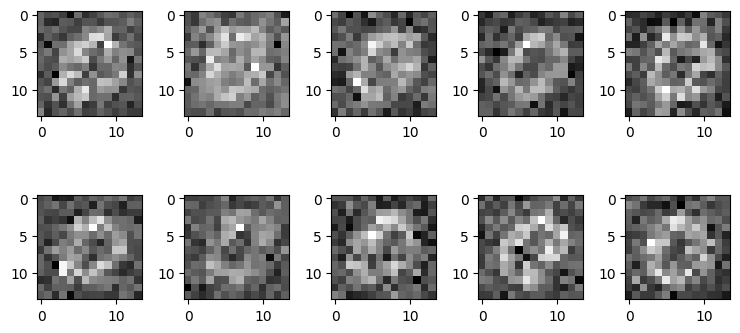

Epoch 31: Train Loss:1025.3201384848737 Val BPD: 7.506534576416016


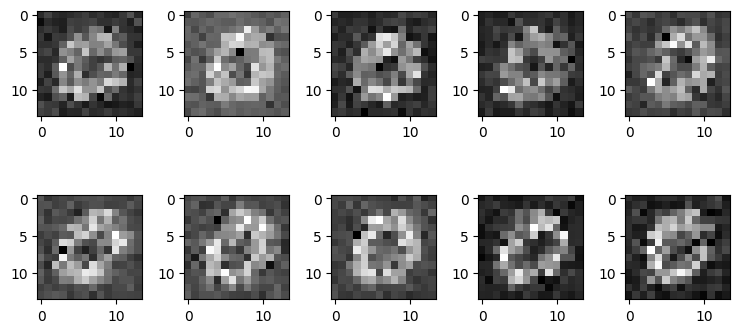

Epoch 41: Train Loss:932.9515030231881 Val BPD: 6.817573547363281


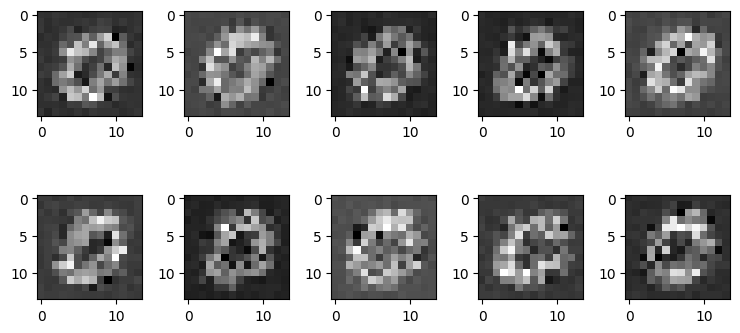

Epoch 51: Train Loss:839.3136349941822 Val BPD: 6.127622127532959


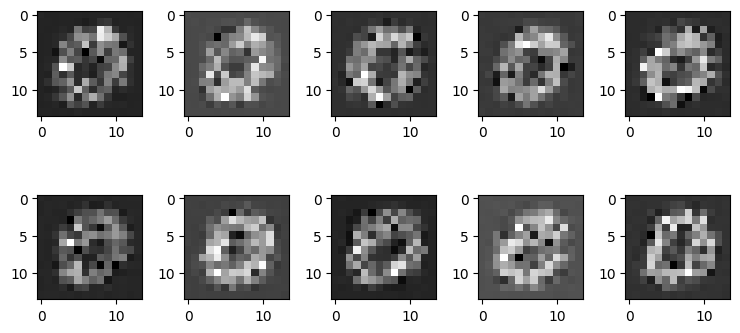

Epoch 61: Train Loss:756.5165080618351 Val BPD: 5.540719985961914


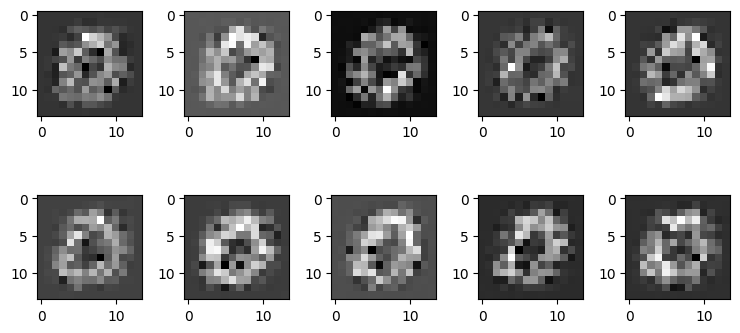

Epoch 71: Train Loss:716.4169817985372 Val BPD: 5.305436134338379


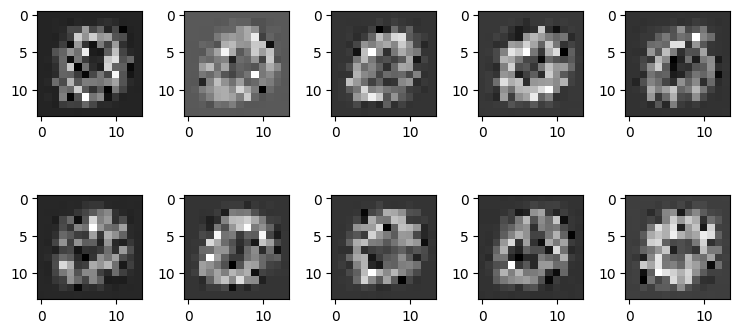

Epoch 81: Train Loss:712.2217160488697 Val BPD: 5.28891658782959


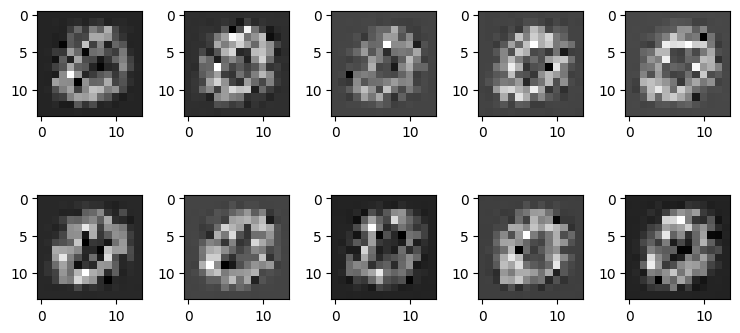

Epoch 91: Train Loss:711.6189289498836 Val BPD: 5.287332534790039


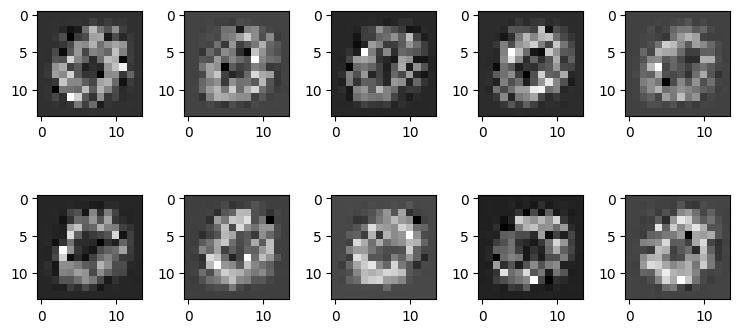

Epoch 101: Train Loss:711.3146245428857 Val BPD: 5.28493070602417


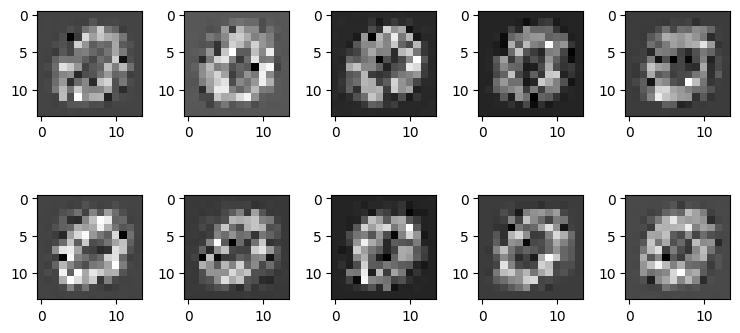

Epoch 111: Train Loss:711.7935518305352 Val BPD: 5.285459995269775


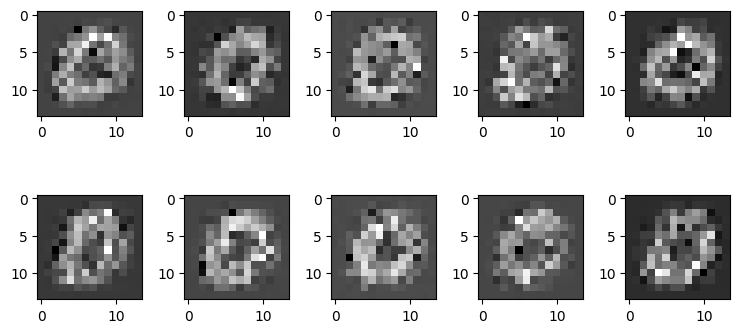

Epoch 121: Train Loss:711.6884298121676 Val BPD: 5.286606311798096


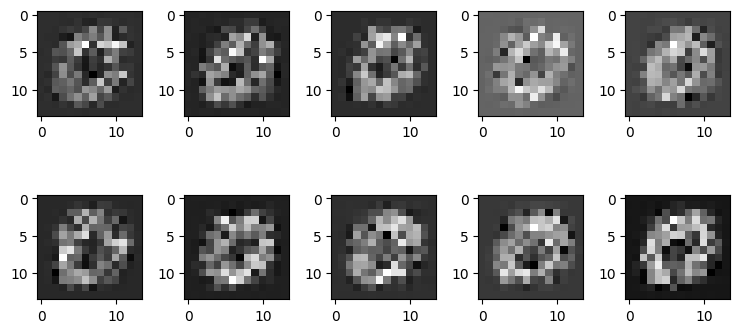

Epoch 131: Train Loss:711.4237865691489 Val BPD: 5.286017894744873


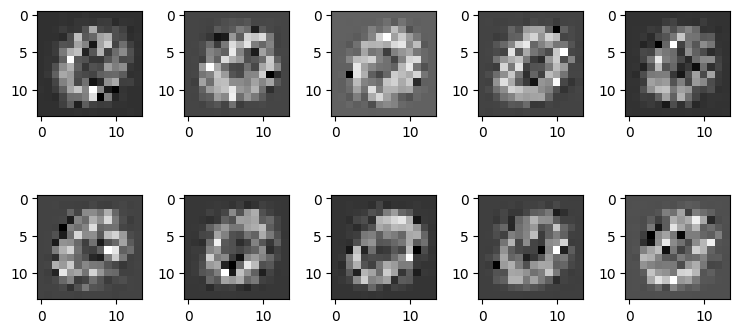

Epoch 141: Train Loss:711.5802144801363 Val BPD: 5.286665439605713


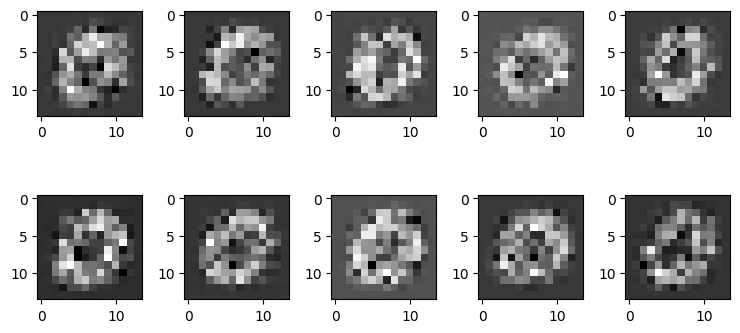

Epoch 151: Train Loss:712.2606434923538 Val BPD: 5.282280445098877


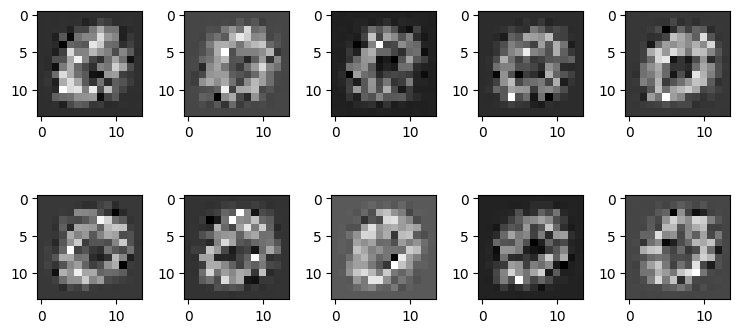

Epoch 161: Train Loss:711.6445026803524 Val BPD: 5.286766529083252


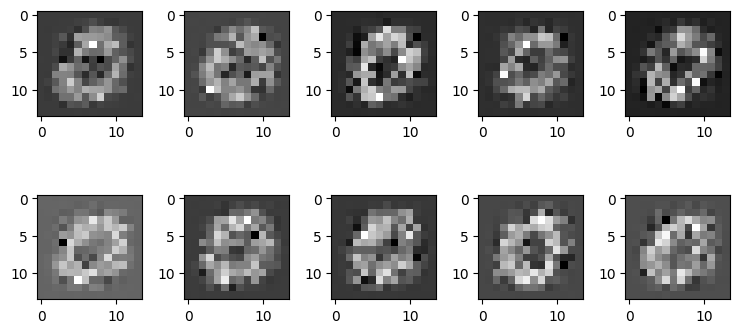

Epoch 171: Train Loss:711.6950112200798 Val BPD: 5.286434173583984


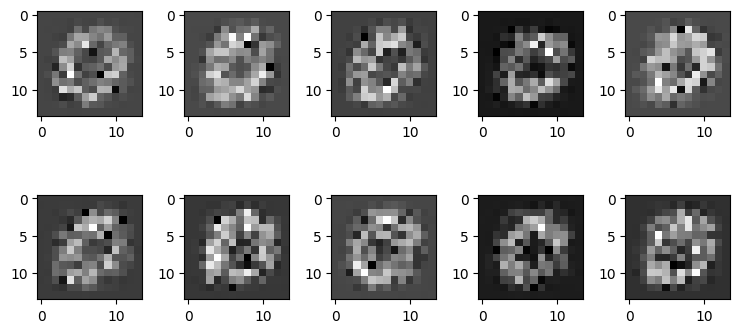

Epoch 181: Train Loss:711.8129999688331 Val BPD: 5.287275791168213


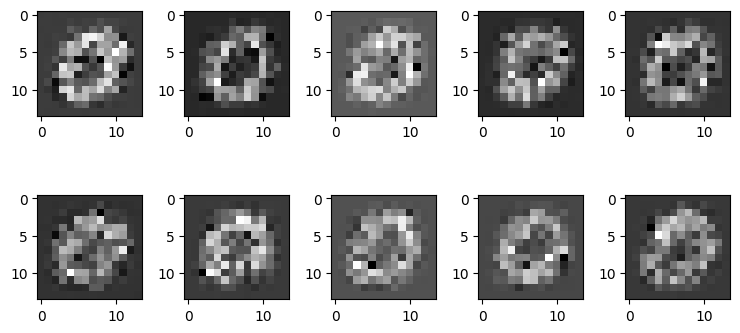

Epoch 191: Train Loss:711.2746763838098 Val BPD: 5.286899089813232


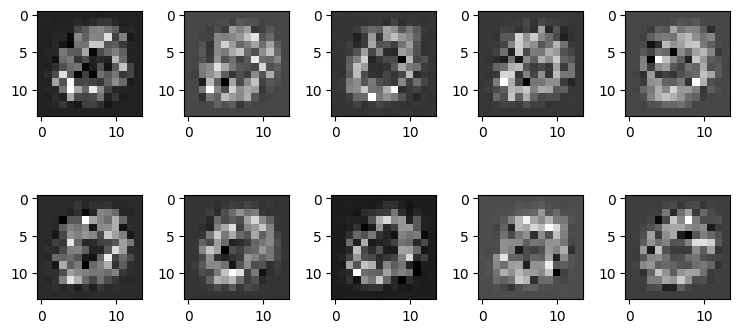

Epoch 201: Train Loss:712.1676804562833 Val BPD: 5.284518241882324


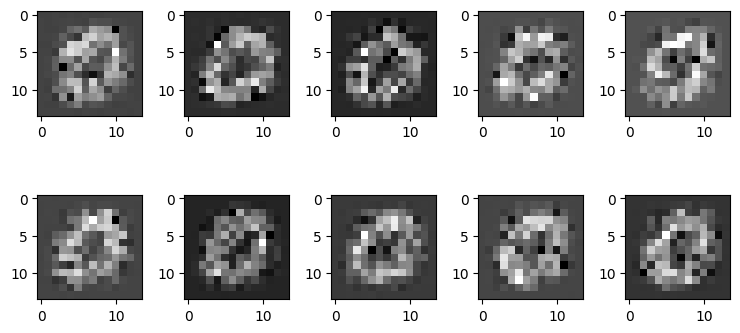

Epoch 211: Train Loss:711.3592892910572 Val BPD: 5.286826133728027


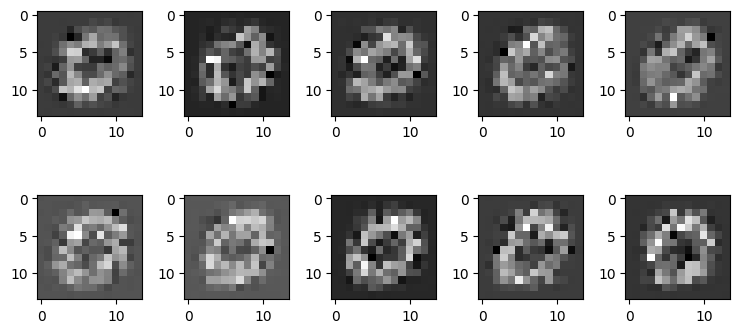

Epoch 221: Train Loss:711.913683302859 Val BPD: 5.287054061889648


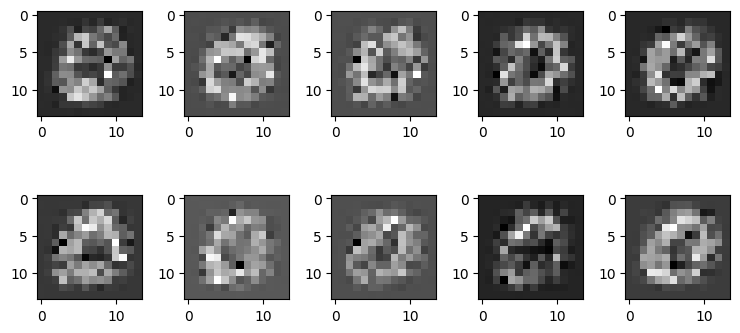

Epoch 231: Train Loss:712.0166638962766 Val BPD: 5.2864556312561035


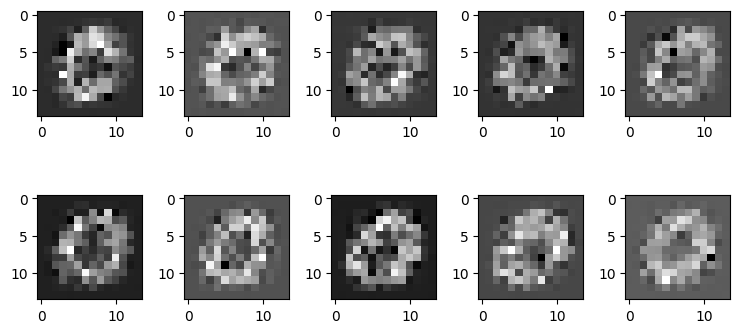

Epoch 241: Train Loss:712.1036221118684 Val BPD: 5.286910057067871


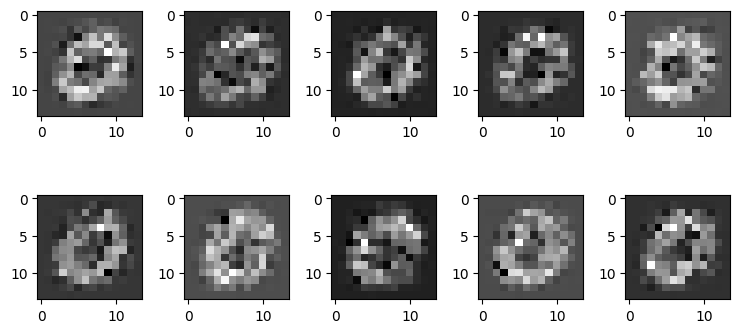

Epoch 251: Train Loss:712.3582503947806 Val BPD: 5.286741256713867


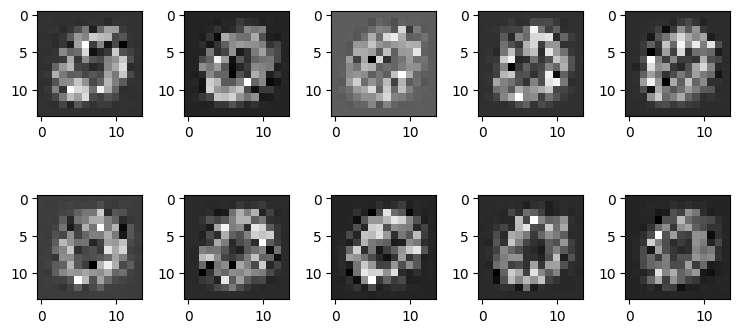

Epoch 261: Train Loss:711.2837693234708 Val BPD: 5.285436630249023


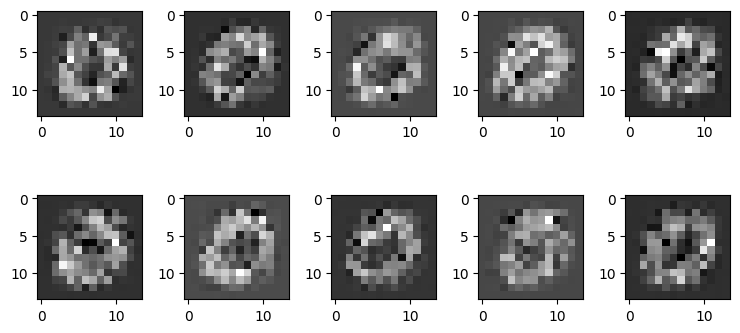

Epoch 271: Train Loss:711.4179271941489 Val BPD: 5.284966945648193


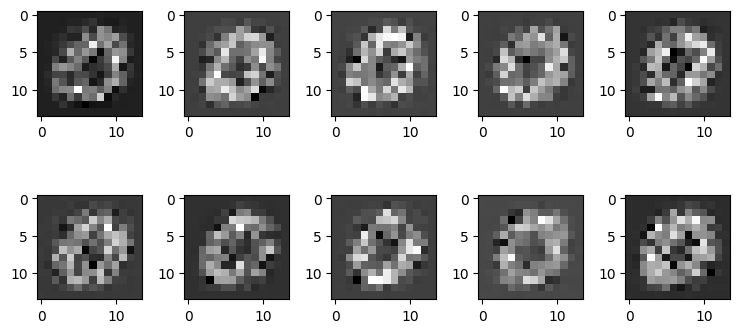

Epoch 281: Train Loss:711.5017245678191 Val BPD: 5.286278247833252


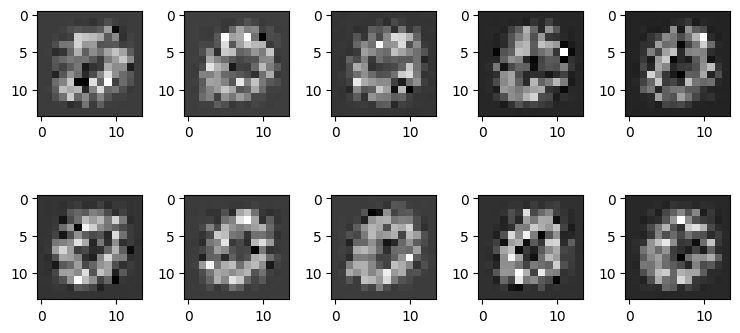

Epoch 291: Train Loss:711.3631513879654 Val BPD: 5.285350322723389


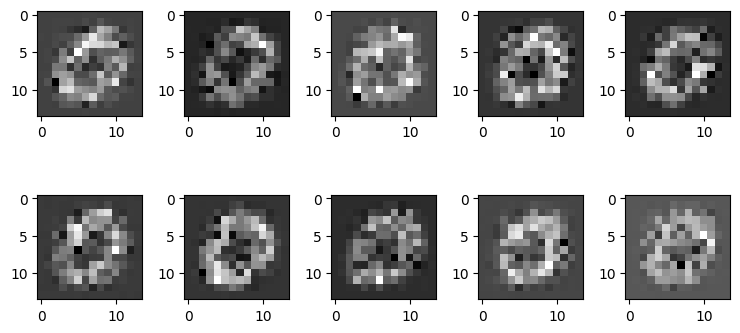

Epoch 301: Train Loss:711.2230224609375 Val BPD: 5.285214900970459


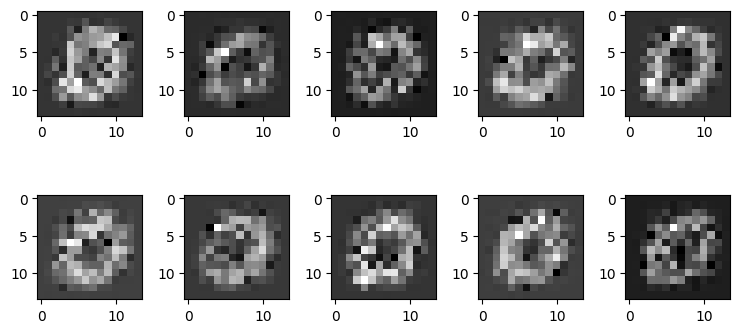

Epoch 311: Train Loss:711.2605097344581 Val BPD: 5.286427974700928


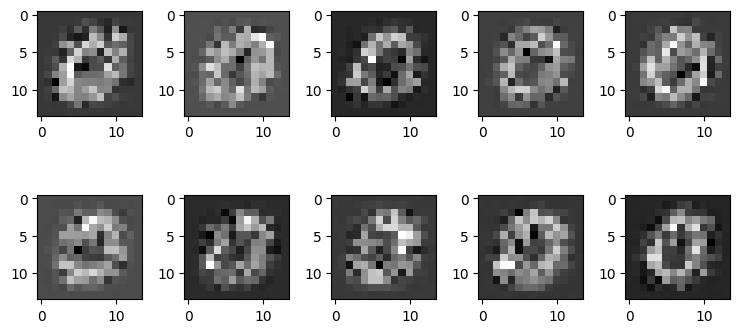

Epoch 321: Train Loss:712.3272977788398 Val BPD: 5.285710334777832


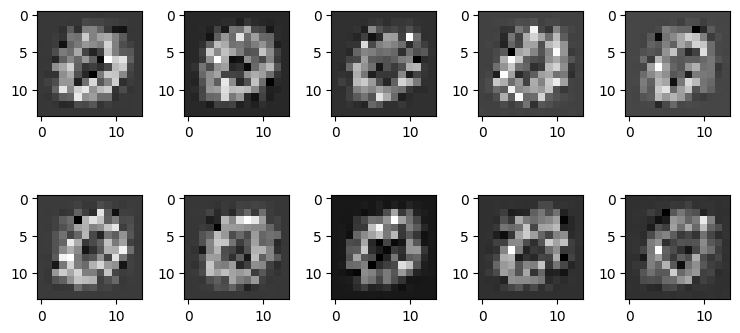

Epoch 331: Train Loss:711.4068356777759 Val BPD: 5.286588668823242


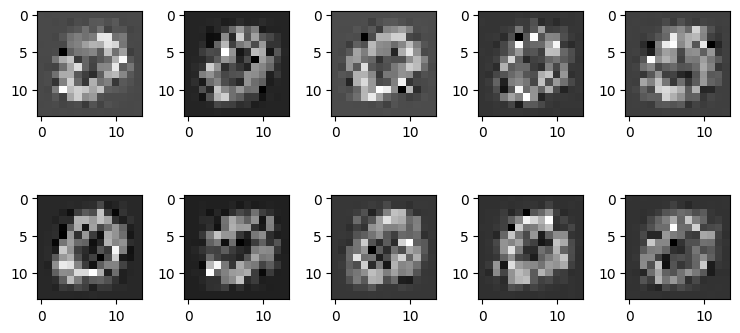

Epoch 341: Train Loss:712.2081259869515 Val BPD: 5.287476539611816


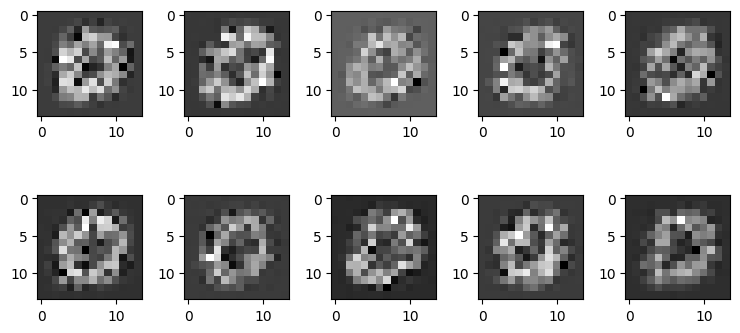

Epoch 351: Train Loss:711.3007500831117 Val BPD: 5.286257743835449


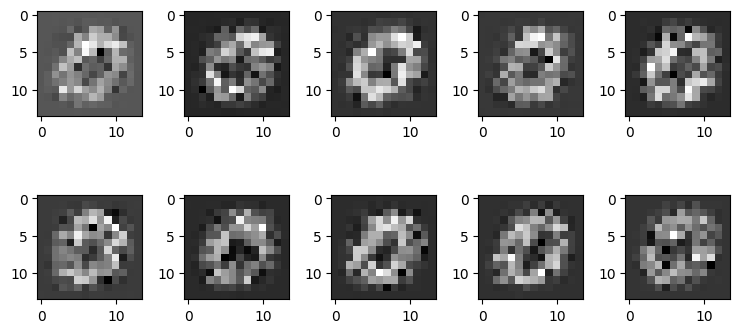

Epoch 361: Train Loss:711.3615540849402 Val BPD: 5.287990570068359


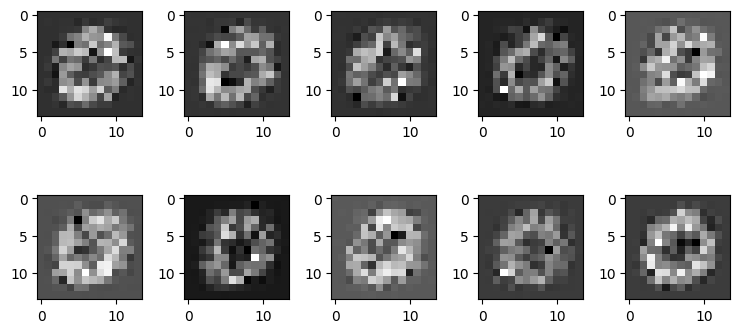

Epoch 371: Train Loss:713.7082870158744 Val BPD: 5.286965847015381


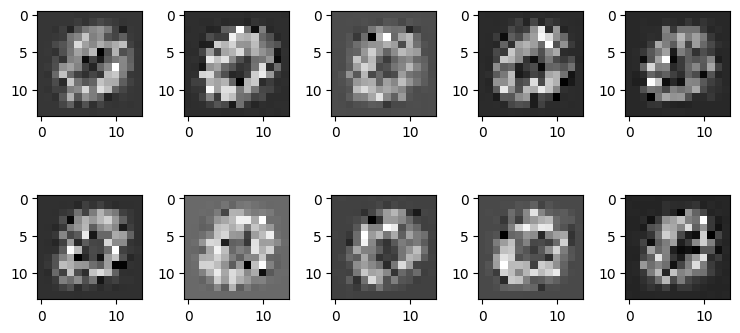

Epoch 381: Train Loss:711.4878721845911 Val BPD: 5.28523588180542


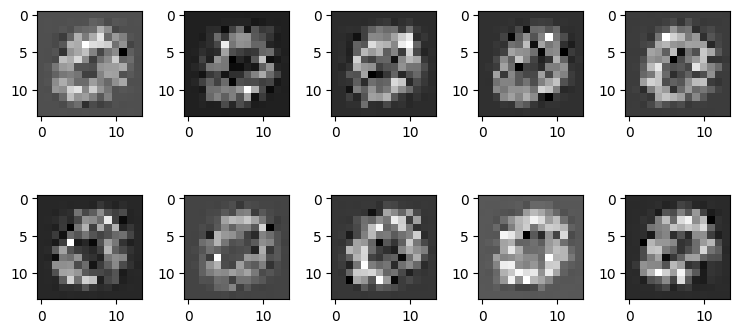

Epoch 391: Train Loss:711.3576166680518 Val BPD: 5.287209510803223


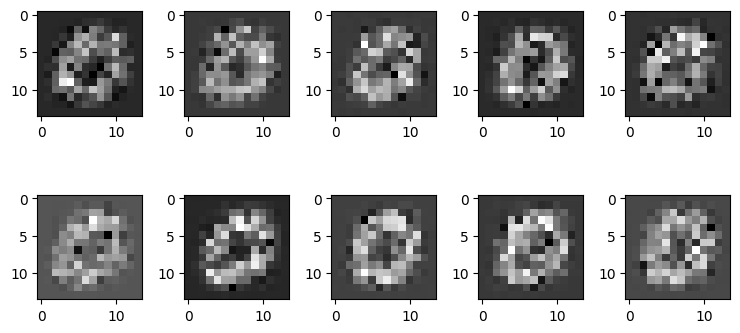

Epoch 401: Train Loss:711.599545742603 Val BPD: 5.288167953491211


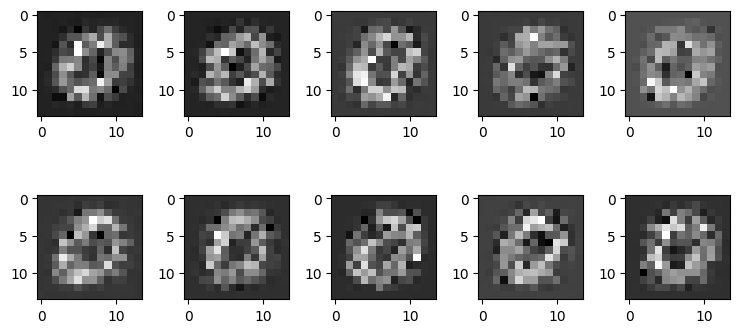

Epoch 411: Train Loss:711.4606738800699 Val BPD: 5.286441802978516


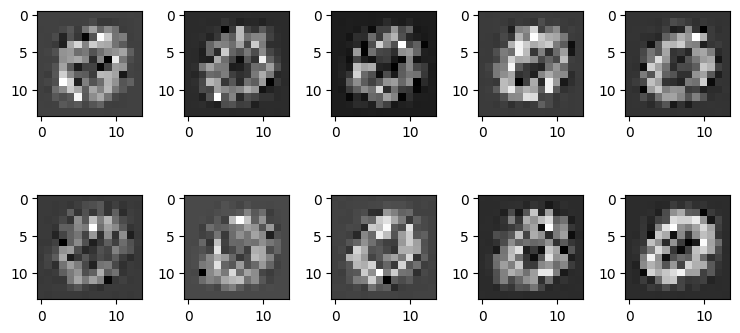

Epoch 421: Train Loss:711.2535582197473 Val BPD: 5.286190509796143


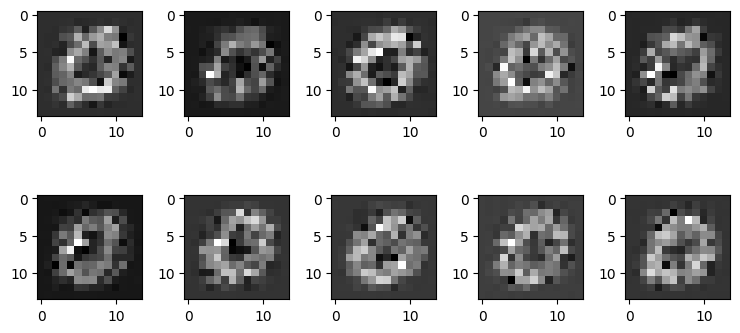

Epoch 431: Train Loss:711.4489213659408 Val BPD: 5.285910129547119


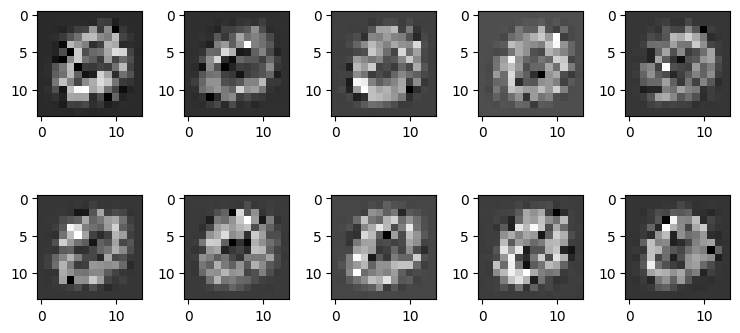

Epoch 441: Train Loss:711.484134755236 Val BPD: 5.285182476043701


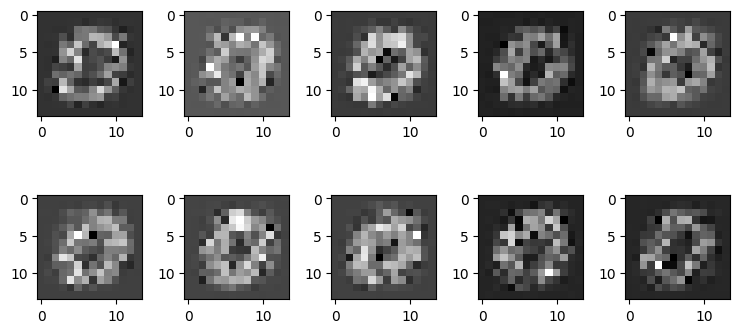

Epoch 451: Train Loss:711.3247018367687 Val BPD: 5.286533832550049


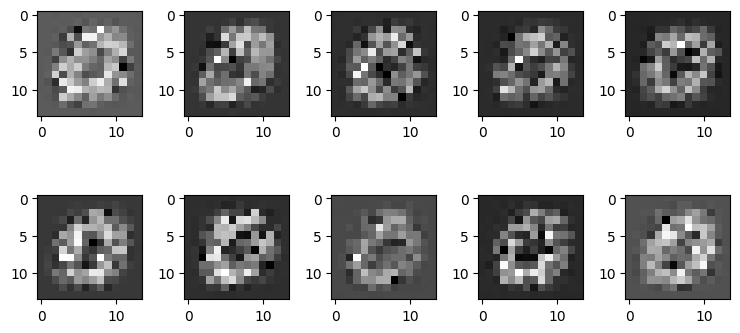

Epoch 461: Train Loss:712.2223302962932 Val BPD: 5.288145542144775


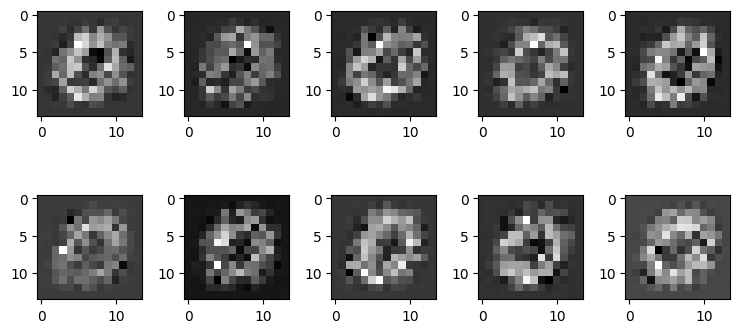

Epoch 471: Train Loss:711.4130287982048 Val BPD: 5.285070419311523


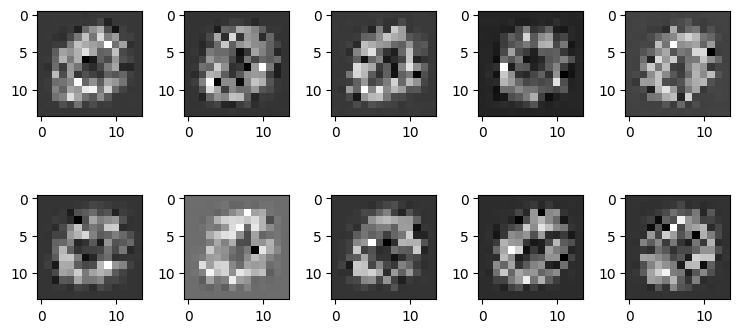

Epoch 481: Train Loss:711.6764487408577 Val BPD: 5.283360481262207


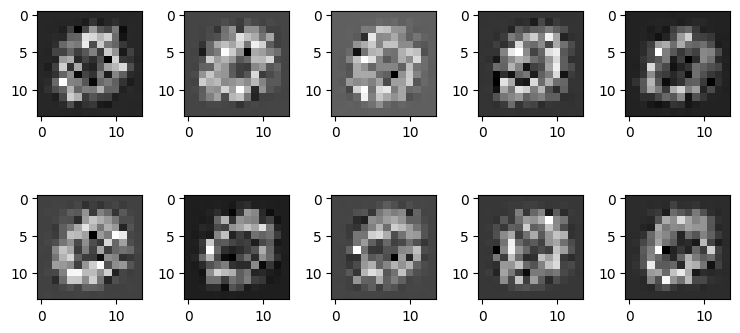

Epoch 491: Train Loss:711.2800020258477 Val BPD: 5.285175323486328


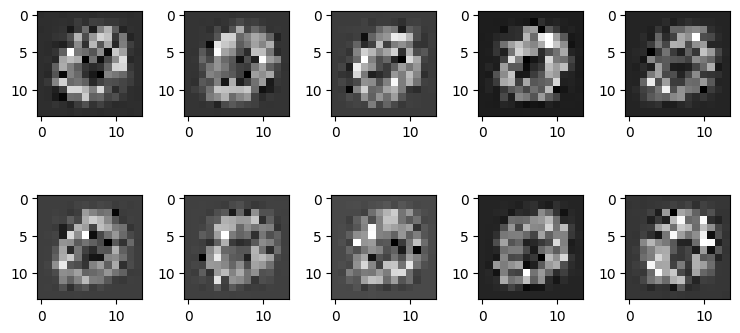

Epoch 501: Train Loss:711.3129830867687 Val BPD: 5.286959648132324


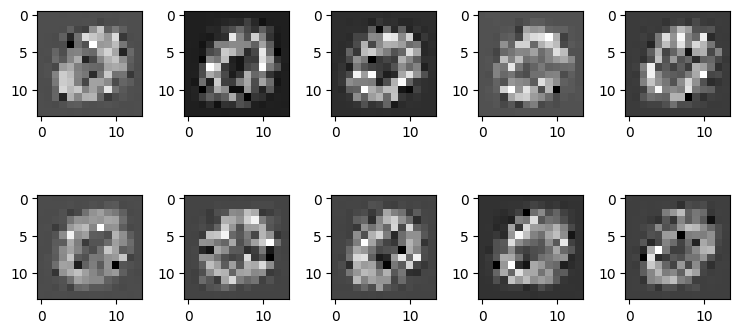

Epoch 511: Train Loss:711.5103305248504 Val BPD: 5.284916400909424


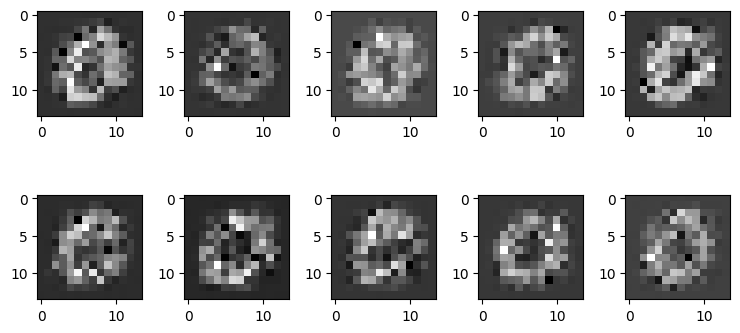

Epoch 521: Train Loss:711.47351983253 Val BPD: 5.284283638000488


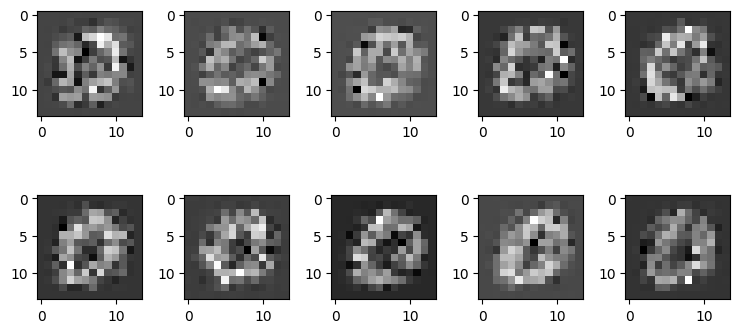

Epoch 531: Train Loss:712.006287919714 Val BPD: 5.284816741943359


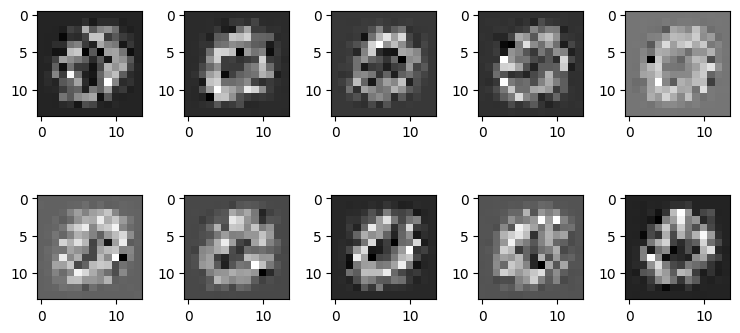

Epoch 541: Train Loss:711.6747306661402 Val BPD: 5.285915374755859


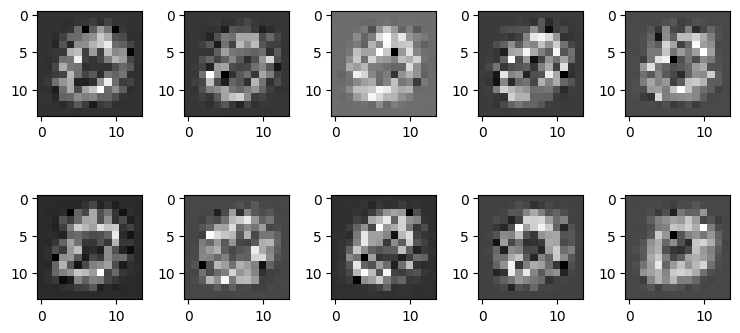

Epoch 551: Train Loss:711.4985935941655 Val BPD: 5.287911891937256


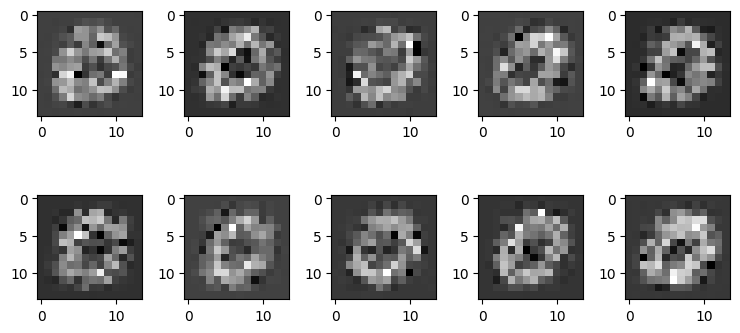

Epoch 561: Train Loss:711.9645061087101 Val BPD: 5.286966323852539


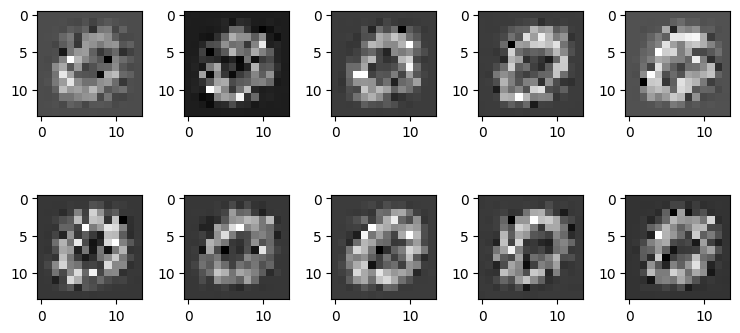

Epoch 571: Train Loss:712.512199239528 Val BPD: 5.2859787940979


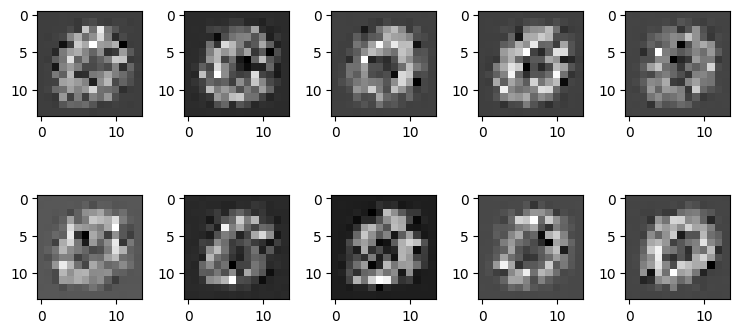

Epoch 581: Train Loss:711.5002025847739 Val BPD: 5.286733150482178


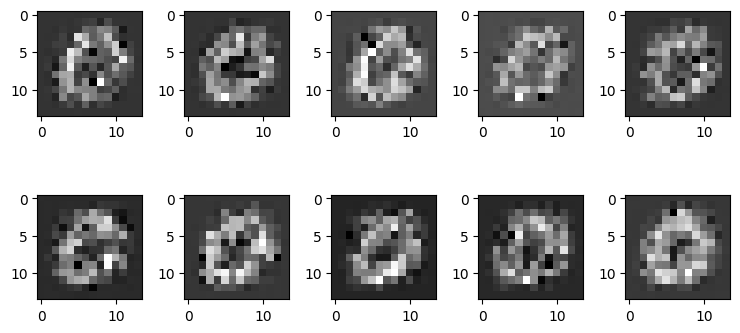

Epoch 591: Train Loss:711.4768559881982 Val BPD: 5.2862677574157715


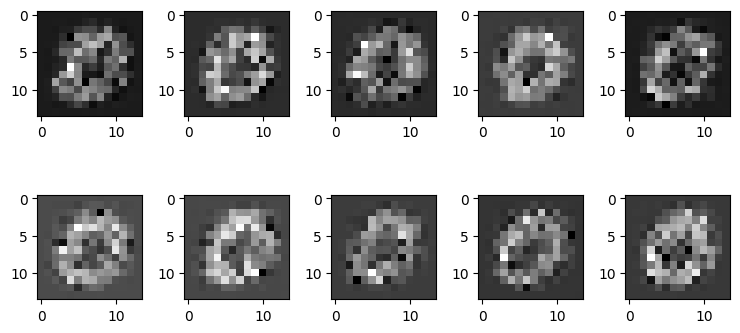

Epoch 601: Train Loss:711.84431360123 Val BPD: 5.2880377769470215


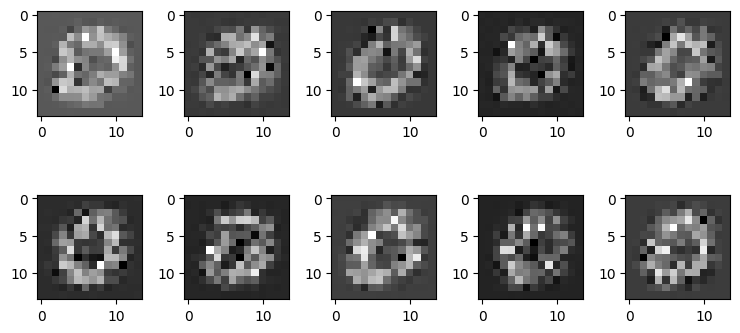

Epoch 611: Train Loss:712.0663153465758 Val BPD: 5.2845869064331055


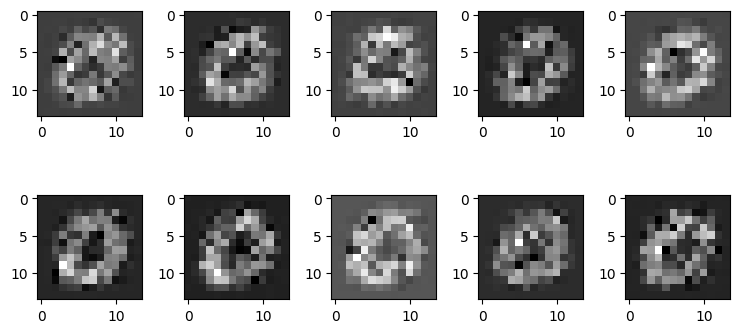

Epoch 621: Train Loss:711.9893448200631 Val BPD: 5.287077903747559


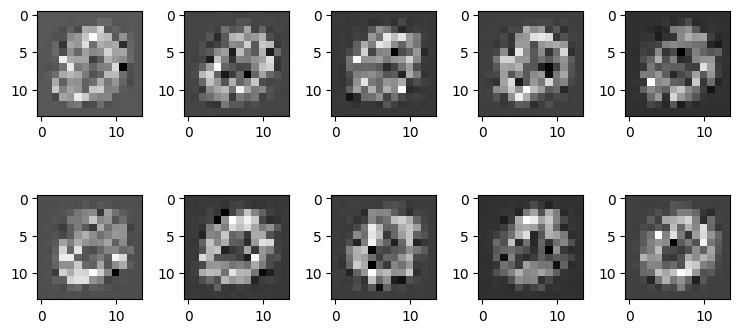

Epoch 631: Train Loss:711.5144133872175 Val BPD: 5.286838054656982


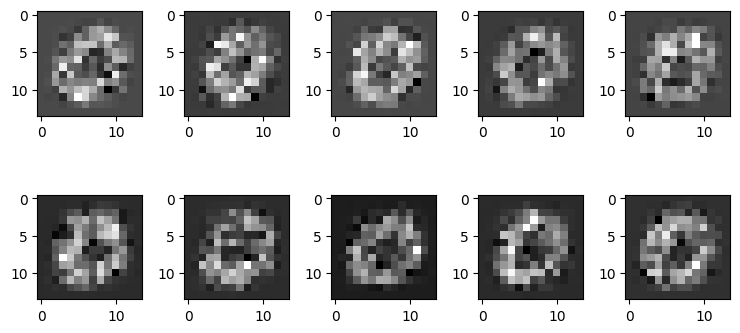

Epoch 641: Train Loss:711.5115681100399 Val BPD: 5.286963939666748


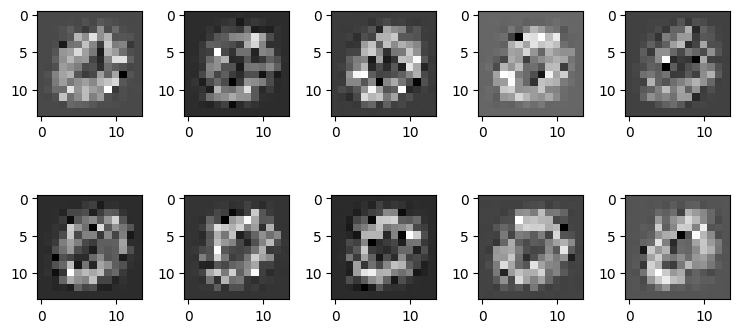

Epoch 651: Train Loss:711.1630833402593 Val BPD: 5.285611152648926


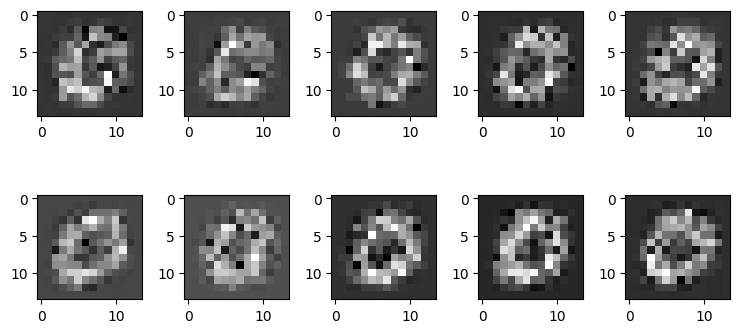

Epoch 661: Train Loss:711.4618971804355 Val BPD: 5.284951686859131


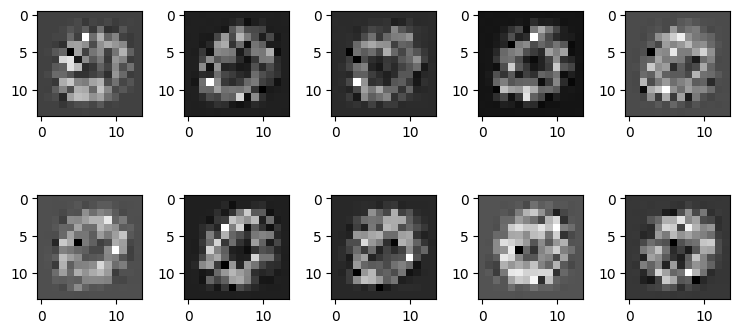

Epoch 671: Train Loss:711.471916036403 Val BPD: 5.284851551055908


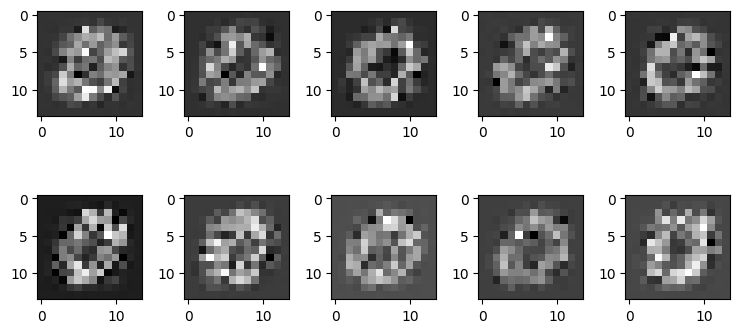

Epoch 681: Train Loss:711.6463856798538 Val BPD: 5.286798000335693


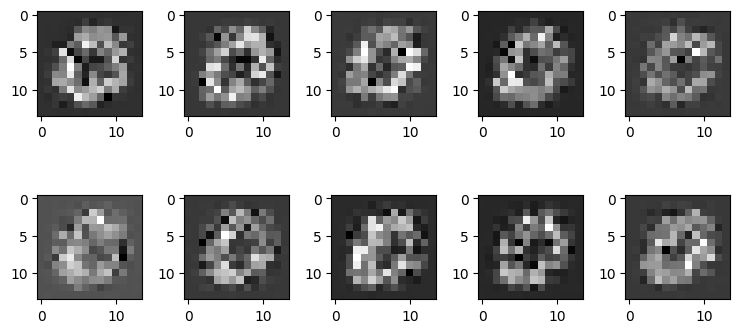

Epoch 691: Train Loss:711.4049189141456 Val BPD: 5.284310817718506


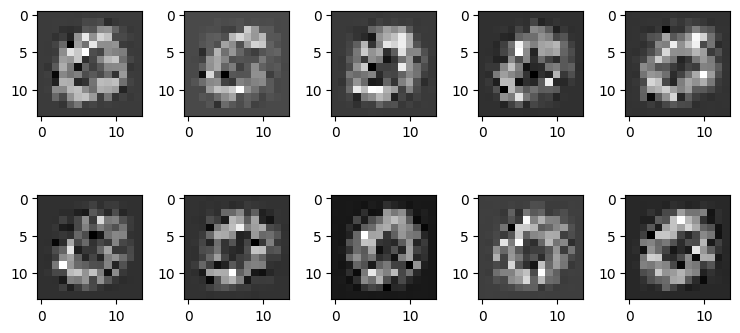

Epoch 701: Train Loss:711.4756002223238 Val BPD: 5.289131164550781


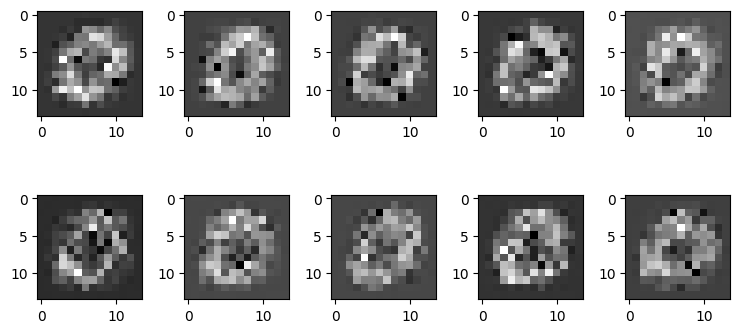

Epoch 711: Train Loss:714.1254701005652 Val BPD: 5.287288665771484


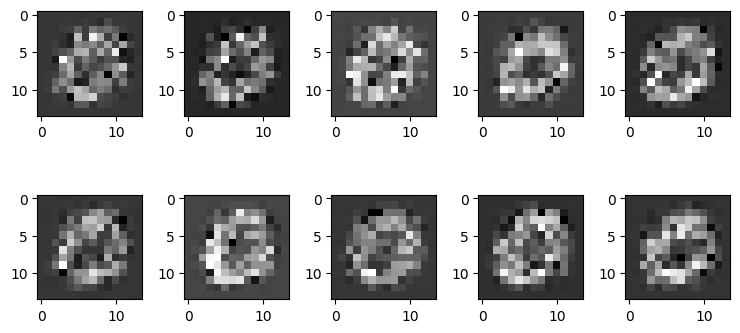

Epoch 721: Train Loss:711.4130547706117 Val BPD: 5.287059307098389


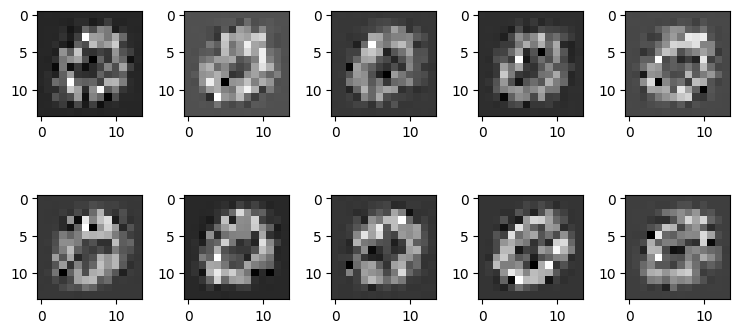

Epoch 731: Train Loss:711.4354092212434 Val BPD: 5.284328460693359


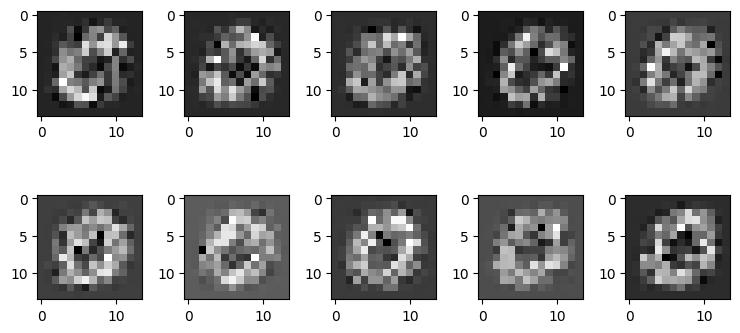

Epoch 741: Train Loss:712.6177744763962 Val BPD: 5.28736686706543


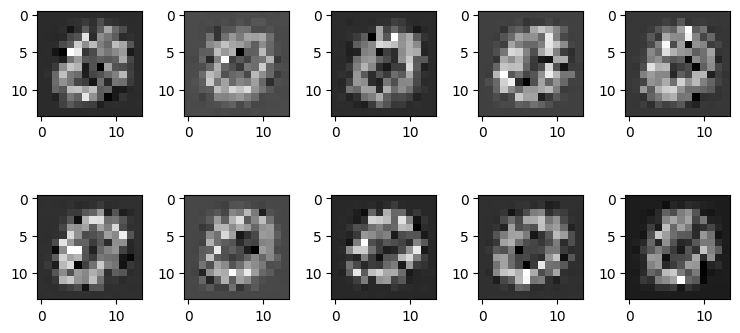

Epoch 751: Train Loss:711.2548945000831 Val BPD: 5.286515712738037


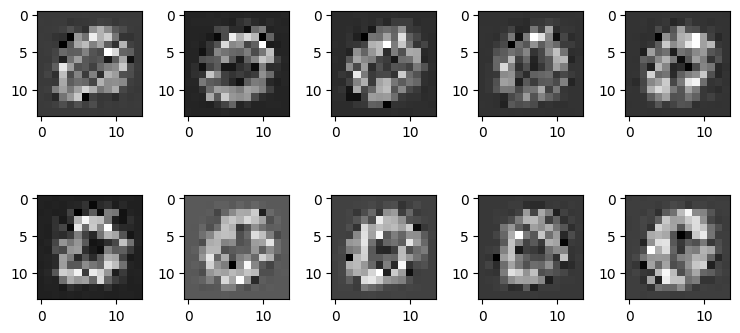

Epoch 761: Train Loss:711.4904966963098 Val BPD: 5.286585330963135


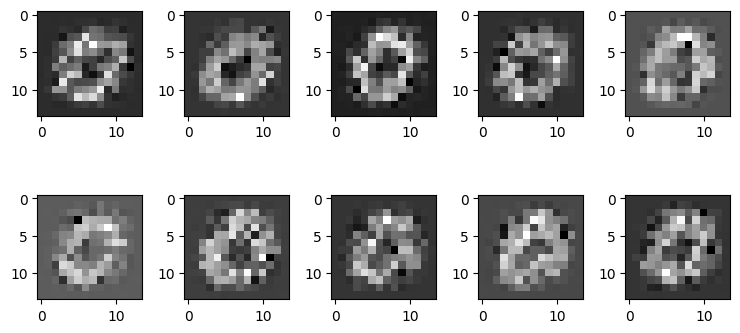

Epoch 771: Train Loss:711.5921877597241 Val BPD: 5.286745548248291


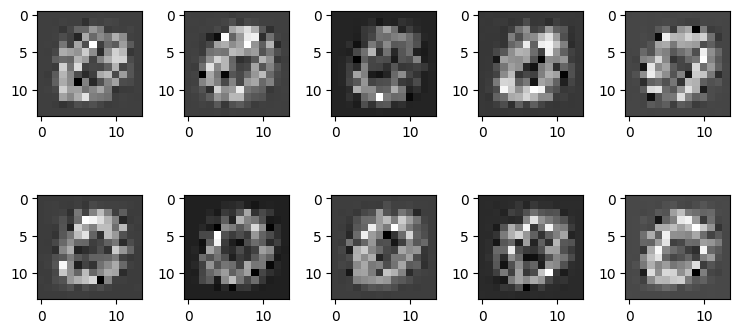

Epoch 781: Train Loss:711.590024258228 Val BPD: 5.285613536834717


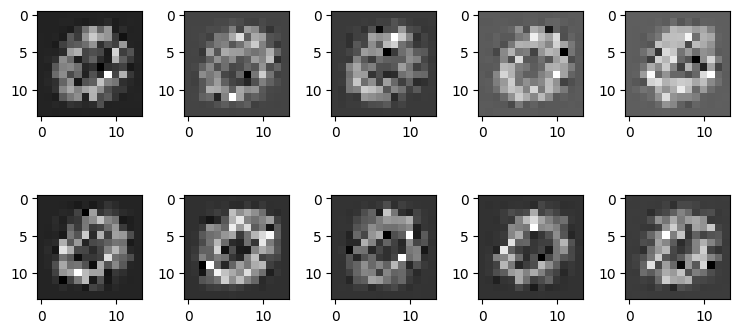

Epoch 791: Train Loss:711.5970809611869 Val BPD: 5.283905029296875


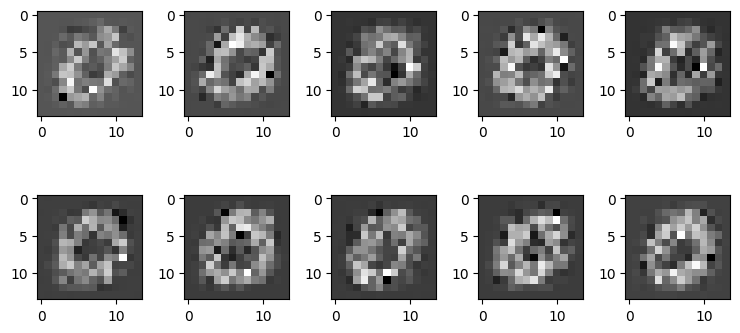

Epoch 801: Train Loss:712.1883518949468 Val BPD: 5.286898612976074


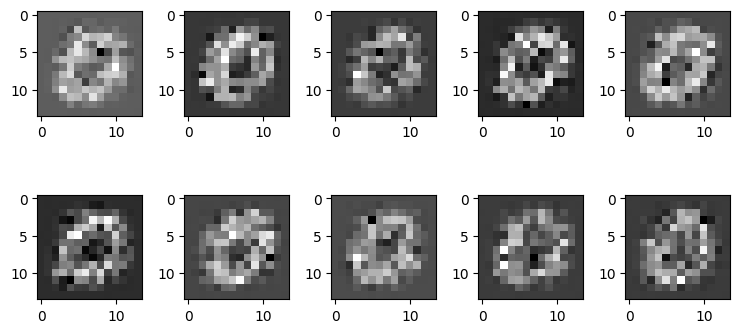

Epoch 811: Train Loss:711.660892567736 Val BPD: 5.285646438598633


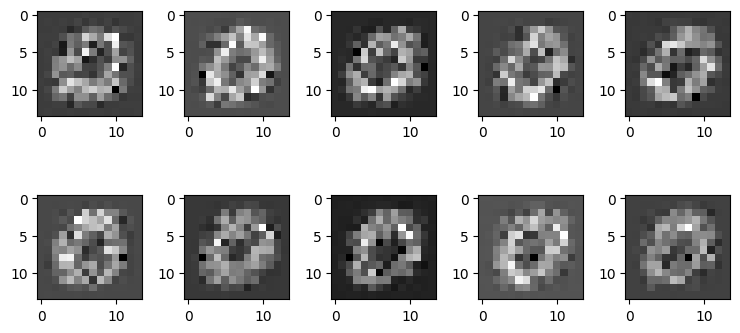

Epoch 821: Train Loss:711.4254565949136 Val BPD: 5.286004543304443


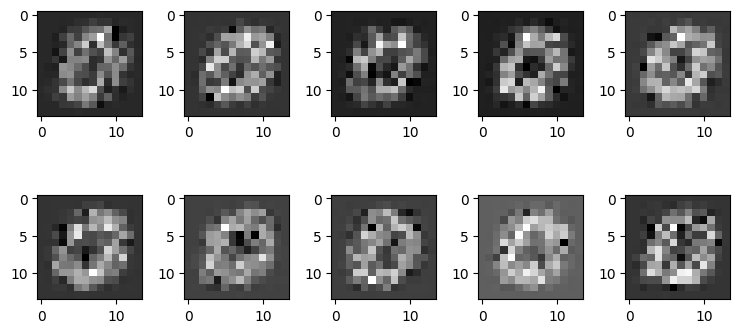

Epoch 831: Train Loss:712.0249309133976 Val BPD: 5.286665439605713


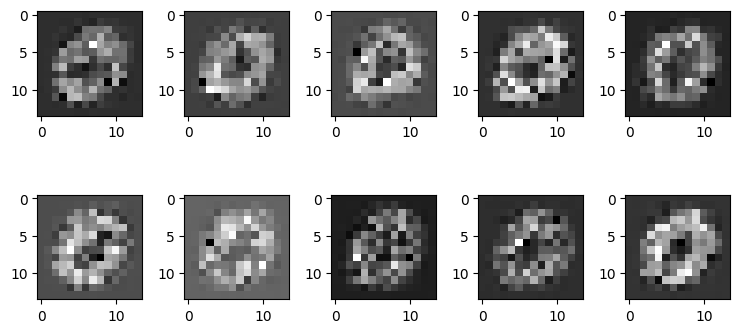

Epoch 841: Train Loss:711.7120802859042 Val BPD: 5.285592079162598


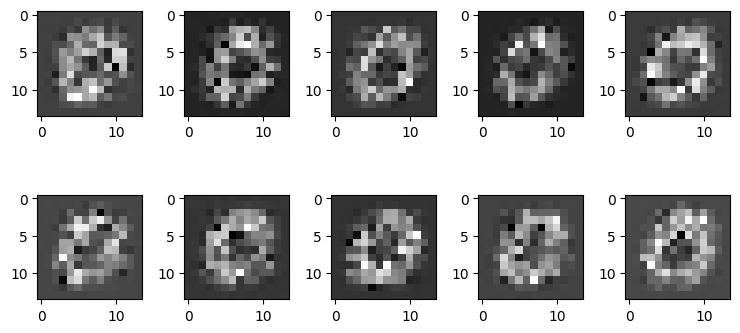

Epoch 851: Train Loss:712.9102939037566 Val BPD: 5.287407875061035


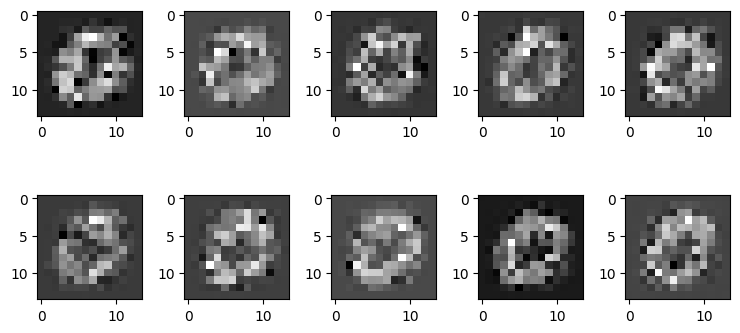

Epoch 861: Train Loss:711.326408223903 Val BPD: 5.285357475280762


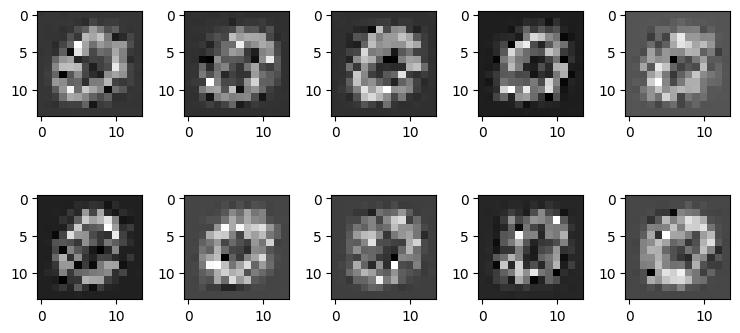

Epoch 871: Train Loss:711.8339934653425 Val BPD: 5.286632061004639


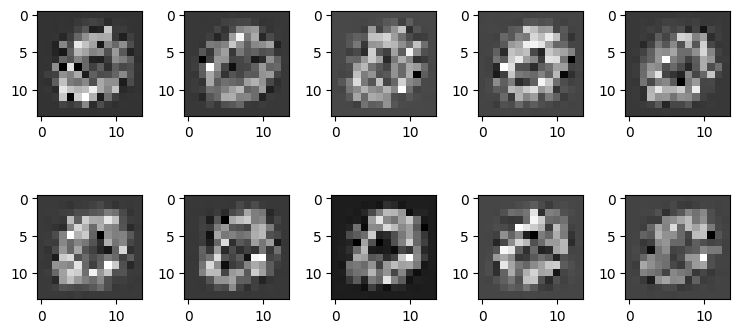

Epoch 881: Train Loss:711.8089950236869 Val BPD: 5.287971019744873


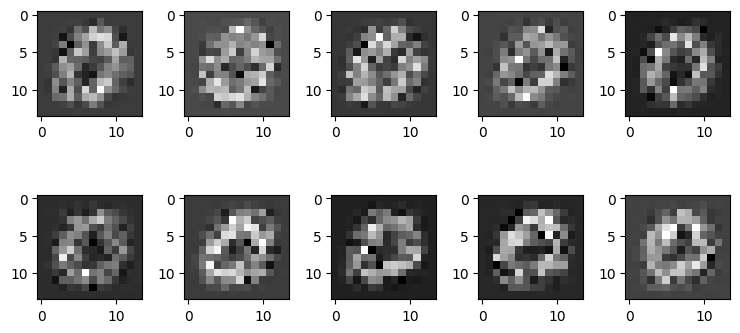

Epoch 891: Train Loss:713.0268710521941 Val BPD: 5.286571979522705


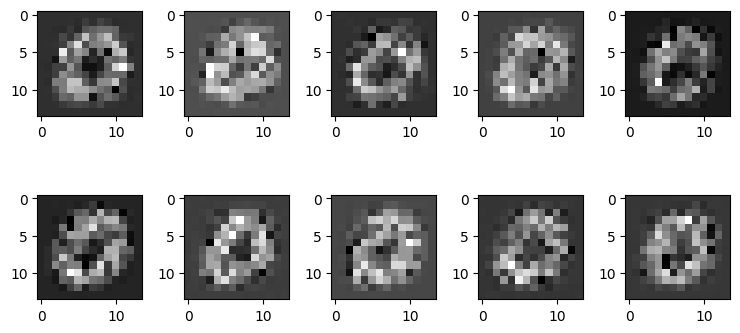

Epoch 901: Train Loss:711.7425679957613 Val BPD: 5.287587642669678


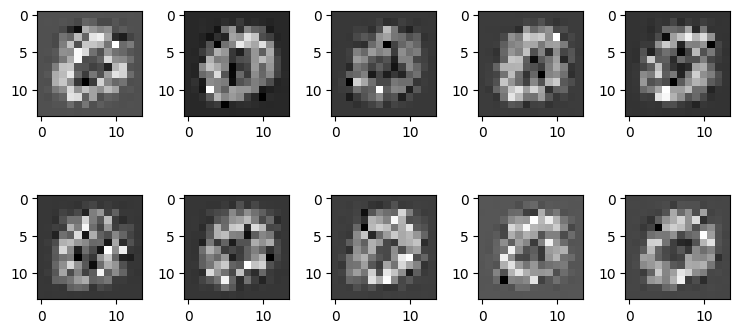

Epoch 911: Train Loss:711.5414727393617 Val BPD: 5.285830497741699


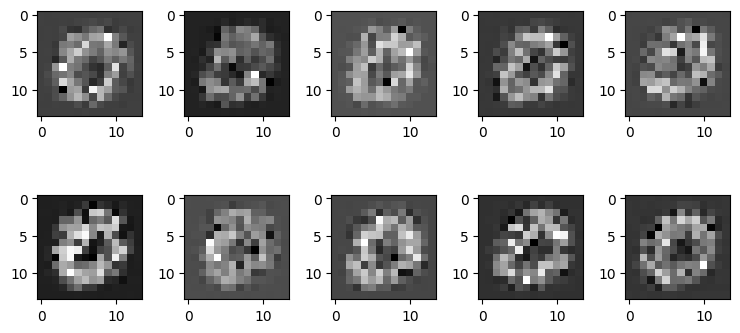

Epoch 921: Train Loss:712.6280829247008 Val BPD: 5.287117958068848


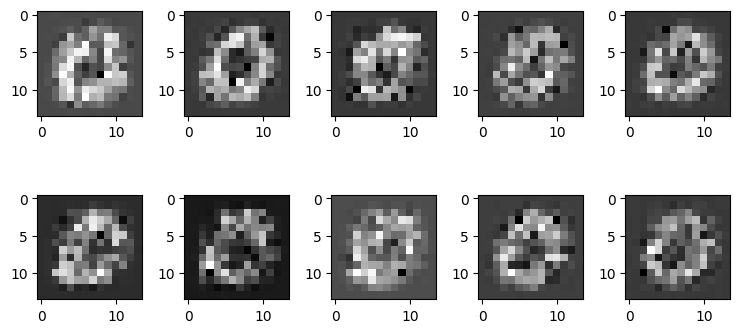

Epoch 931: Train Loss:711.4279434528756 Val BPD: 5.286687850952148


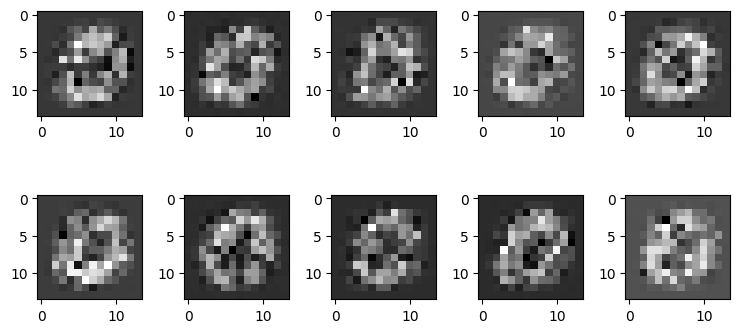

Epoch 941: Train Loss:711.574353806516 Val BPD: 5.28675651550293


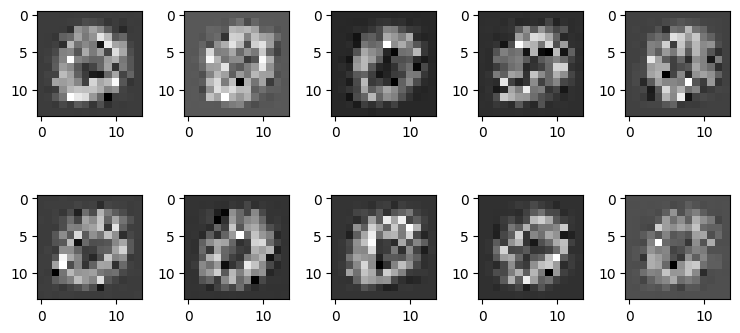

Epoch 951: Train Loss:711.4911213326961 Val BPD: 5.2879228591918945


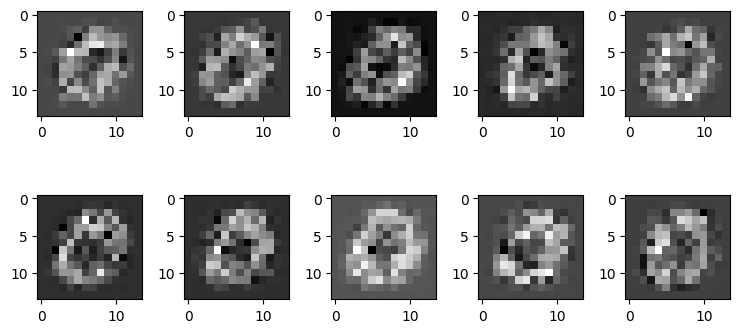

Epoch 961: Train Loss:711.3607593292886 Val BPD: 5.286709308624268


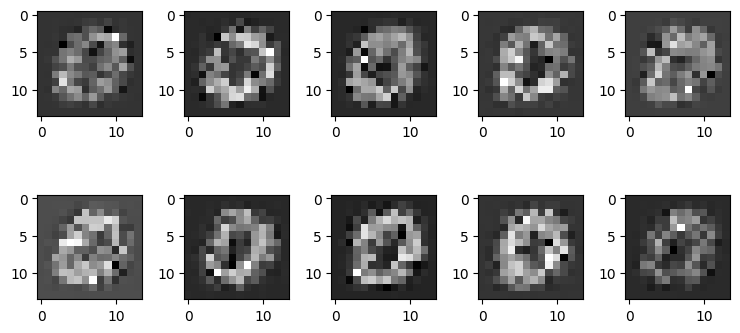

Epoch 971: Train Loss:712.3166309113199 Val BPD: 5.2868428230285645


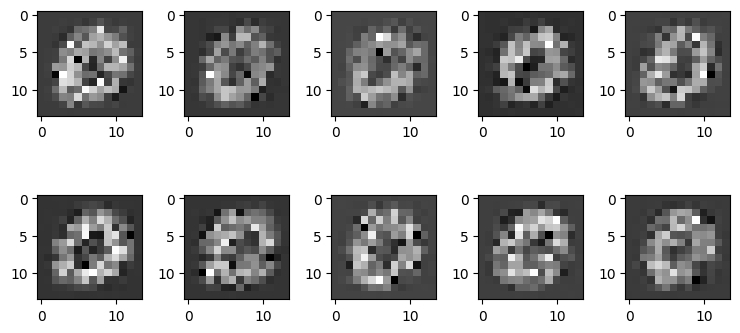

Epoch 981: Train Loss:711.3712885430518 Val BPD: 5.287564277648926


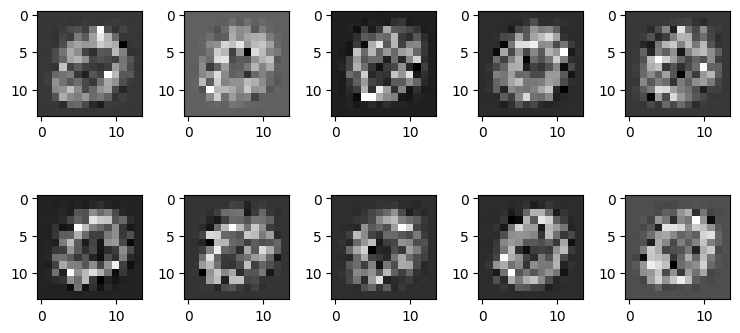

Epoch 991: Train Loss:711.7330620948304 Val BPD: 5.286219120025635


In [28]:
device = 'cpu'
flow = RealNVP(14*14, num_steps=21).to(device)
optim = torch.optim.AdamW(flow.parameters(), lr=1e-5)
epochs = 1000
iters = 0
bits = 8
for ep in range(epochs):
    total_loss = 0.
    iters = 0
    for x, _ in train_loader:
        x = (x * 255).long()
        u = torch.rand_like(x.float())
        x = x + u
        x = x / (2 ** bits)
        x = x.flatten(start_dim=1)
        y = 2 * x - 1
        optim.zero_grad()
        log_px = flow.log_prob(x.to(device)) - np.log((2 ** bits)) * (14 * 14)
        loss = - (log_px).mean()
        loss.backward()
        optim.step()
        z = flow(x.to(device))
        iters += 1
        total_loss += loss.item()
    if ep % 10 == 0:
        with torch.no_grad():
            val_iters = 0
            total_bpd = 0.
            for x, _ in test_loader:
                x = (x * 255).long()
                u = torch.rand_like(x.float())
                x = x + u
                x = x / (2 ** bits)
                x = x.flatten(start_dim=1)
                log_px = flow.log_prob(x.to(device)) - np.log((2 ** bits)) * (14 * 14)
                bpd = -(log_px).mean().cpu() / (np.log(2) * (14 * 14))
                total_bpd += bpd
                val_iters += 1
        samples = flow.sample(10).detach().cpu()
        samples = torch.unflatten(samples, dim=1, sizes=(14, 14)).unsqueeze(1)

        plot_mnist(samples[:, 0], 2, 5)

        print(f"Epoch {ep+1}: Train Loss:{total_loss / iters} Val BPD: {total_bpd / val_iters}")

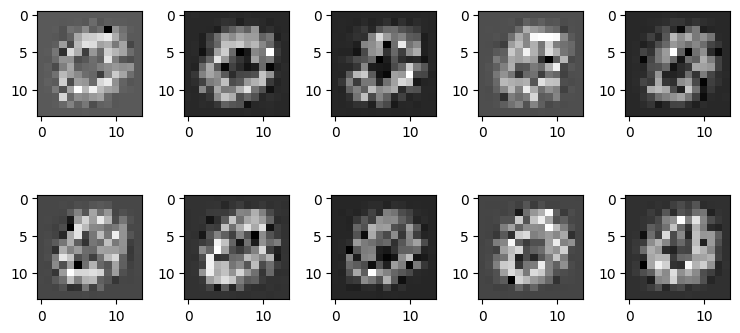

In [29]:
samples = flow.sample(10).detach().cpu() 
samples = torch.unflatten(samples, dim=1, sizes=(14, 14)).unsqueeze(1) 
plot_mnist(samples[:,0], 2, 5)

"top"

## Bonus zadatak

Predložite implementaciju konvolucijskog normalizirajućeg toka.